# **Project Name** - Paisabazaar Credit Score Analysis (EDA)

##### **Project Type** - Exploratory Data Analysis
##### **Contribution** - Individual
##### **Domain** - Banking & Financial Services (credit risk)
##### **Tools** - Python, Pandas, NumPy, Matplotlib, Seaborn, Plotly, SciPy, Google Colab

## Project Summary

Paisabazaar helps people find and apply for loans and credit cards. Before suggesting any financial product, it is important to check the customer's credit score. Credit scores are divided into three categories: Poor, Standard, and Good.

In this project, I have analysed around 100,000 monthly customer records from approximately 12,500 customers over 8 months. The main aim is to understand which financial details and customer habits affect their credit score.

The project is divided into four main steps:

1. **Understanding the Project**: I created four hypotheses (H1–H4) to identify the factors that may affect a customer's credit score.

2. **Data Visualization**: I used different charts to understand the data, such as univariate, bivariate and multivariate analysis. I also used statistical tests like Spearman Correlation, Kruskal-Wallis, Chi-square and Cramér's V to support my findings.

3. **Finding Insights**: I checked all four hypotheses using the data, identified the most important factors affecting credit scores and understood the differences between Good, Standard and Poor customers.

4. **Business Recommendations**: Based on the analysis, I suggested some useful actions for Paisabazaar's risk, product and customer-advisory teams.

**Data Cleaning:**

Before starting the analysis, I cleaned the dataset because it contained many errors, such as missing values, incorrect text entries (`_______`, `!@9#%8`), numbers stored as text (`45_`) and unrealistic values like age 7,000 or 1,400 credit cards.

Since each customer has records for 8 different months, I first used that customer's other monthly records to correct inconsistent or missing values. If the information was still unavailable, I used a general method to fill the missing values.

Overall, this project helped me understand customer financial behaviour, identify the main factors affecting credit scores and find useful insights that can help Paisabazaar make better decisions.

# **Problem Statement**

Paisabazaar needs to understand what drives an individual's credit score class so that it can assess creditworthiness
more accurately, reduce loan-default risk and give customers personalised advice. The specific questions are:

**Assumptions to test (Project statement understanding)**
- **H1** – Does a higher annual income correlate with a higher credit score?
- **H2** – Does the credit utilization ratio have a greater impact on credit score than the total number of loans taken?
- **H3** – Is a higher number of credit cards associated with a higher credit score, assuming utilization is managed well?
- **H4** – Is there a negative correlation between the number of delayed payments and credit score?

**Visualization questions**
- **V1** – What is the distribution of credit scores across different age groups?
- **V2** – How does annual income vary with credit score ranges?
- **V3** – Are there noticeable trends or seasonal patterns in credit scores by month?

#### **Define Your Business Objective?**

Identify the customer attributes and behaviours that most strongly separate Good, Standard and Poor credit scores,
validate the team's assumptions with evidence, and turn the findings into actions that (a) sharpen credit assessment
and loan approval, (b) reduce default risk, and (c) power personalised product recommendations and financial advice.

# ***Let's Begin !***

## ***1. Know Your Data***

In [ ]:
# Plotly ships with Colab; uncomment if running somewhere it is missing
# !pip install -q plotly

import os, re, calendar, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import plotly.express as px
import plotly.io as pio
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
    pio.renderers.default = "colab"
except ImportError:
    IN_COLAB = False
    pio.renderers.default = "notebook_connected"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

SCORE_ORDER = ["Poor", "Standard", "Good"]
SCORE_MAP = {"Poor": 0, "Standard": 1, "Good": 2}
def is_text(s):
    # True for text columns in both pandas 2 (object) and pandas 3 (str)
    return pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s)

PALETTE = {"Poor": "#d1495b", "Standard": "#edae49", "Good": "#2e933c"}   # red / amber / green = risk signal

In [ ]:
!pip install -q gdown

import gdown
import pandas as pd

file_id = "12hgH6e8pPKHruEZL4bwOZQ6-BH8FUkSA"

url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, "credit_score.csv", quiet=False)

df = pd.read_csv("credit_score.csv")


Downloading...
From: https://drive.google.com/uc?id=12hgH6e8pPKHruEZL4bwOZQ6-BH8FUkSA
To: /content/credit_score.csv
100%|██████████| 30.8M/30.8M [00:00<00:00, 66.5MB/s]


### Dataset Loading

In [ ]:
required = {"Customer_ID", "Month", "Credit_Score", "Annual_Income", "Credit_Utilization_Ratio", "Num_of_Loan",
            "Num_Credit_Card", "Num_of_Delayed_Payment", "Age"}
missing_cols = required - set(df.columns.str.strip())
if missing_cols:
    raise KeyError(f"Dataset is missing expected columns: {sorted(missing_cols)}")
df.columns = df.columns.str.strip()
print(f"Loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")

Loaded: 100,000 rows x 28 columns


### Dataset First View

In [ ]:
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.00,"821,000,265.00",Scientist,"19,114.12","1,824.84",3.00,4.00,3.00,4.00,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.00,7.00,11.27,4.00,Good,809.98,26.82,265.00,No,49.57,21.47,High_spent_Small_value_payments,312.49,Good
1,5635,3392,2,Aaron Maashoh,23.00,"821,000,265.00",Scientist,"19,114.12","1,824.84",3.00,4.00,3.00,4.00,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.00,4.00,11.27,4.00,Good,809.98,31.94,266.00,No,49.57,21.47,Low_spent_Large_value_payments,284.63,Good
2,5636,3392,3,Aaron Maashoh,23.00,"821,000,265.00",Scientist,"19,114.12","1,824.84",3.00,4.00,3.00,4.00,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.00,7.00,11.27,4.00,Good,809.98,28.61,267.00,No,49.57,21.47,Low_spent_Medium_value_payments,331.21,Good
3,5637,3392,4,Aaron Maashoh,23.00,"821,000,265.00",Scientist,"19,114.12","1,824.84",3.00,4.00,3.00,4.00,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5.00,4.00,6.27,4.00,Good,809.98,31.38,268.00,No,49.57,21.47,Low_spent_Small_value_payments,223.45,Good
4,5638,3392,5,Aaron Maashoh,23.00,"821,000,265.00",Scientist,"19,114.12","1,824.84",3.00,4.00,3.00,4.00,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6.00,4.00,11.27,4.00,Good,809.98,24.80,269.00,No,49.57,21.47,High_spent_Medium_value_payments,341.49,Good


### Dataset Rows & Columns count

In [ ]:
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")
if "Customer_ID" in df:
    print(f"Unique customers : {df['Customer_ID'].nunique():,}")
    print(f"Records per customer (typical): {df.groupby('Customer_ID').size().median():.0f}")

Rows    : 100,000
Columns : 28
Unique customers : 12,500
Records per customer (typical): 8


### Dataset Information

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  object 
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              100000 non-null  ob

#### Duplicate Values

In [ ]:
print(f"Fully duplicated rows : {df.duplicated().sum():,}")
if "ID" in df:
    print(f"Duplicated record IDs : {df['ID'].duplicated().sum():,}")

Fully duplicated rows : 0
Duplicated record IDs : 0


#### Missing Values/Null Values

In [ ]:
# Raw credit data hides missing values behind placeholder strings, so count both kinds.
PLACEHOLDERS = ["_______", "!@9#%8", "_", "", "__10000__", "NA", "N/A", "nan", "NaN"]

def placeholder_count(s):
    if not is_text(s):
        return 0
    return s.astype(str).str.strip().isin(PLACEHOLDERS).sum()

missing = pd.DataFrame({
    "null_values": df.isna().sum(),
    "placeholder_values": df.apply(placeholder_count),
})
missing["total_missing_%"] = (missing.sum(axis=1) / len(df) * 100).round(2)
missing = missing[missing[["null_values", "placeholder_values"]].sum(axis=1) > 0].sort_values("total_missing_%", ascending=False)
display(missing if len(missing) else "No missing or placeholder values found")

'No missing or placeholder values found'

In [ ]:
# Visualizing the missing values
if len(missing):
    fig, ax = plt.subplots(figsize=(10, max(3, 0.4 * len(missing))))
    missing["total_missing_%"].sort_values().plot.barh(ax=ax, color="#4c72b0")
    ax.set_title("Missing / placeholder values by column (raw data)")
    ax.set_xlabel("% of rows"); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    for i, v in enumerate(missing["total_missing_%"].sort_values()):
        ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print("Nothing to plot - dataset has no missing values.")

Nothing to plot - dataset has no missing values.


### What did you know about your dataset?

In [ ]:
num_text_cols = [c for c in df.columns if is_text(df[c]) and c not in ("Name", "Credit_Score")
                 and pd.to_numeric(df[c].astype(str).str.strip("_ "), errors="coerce").notna().mean() > 0.8]
md_lines = [
    f"- The dataset has **{df.shape[0]:,} rows and {df.shape[1]} columns**"
    + (f" covering **{df['Customer_ID'].nunique():,} customers**, each observed over several months - it is a monthly panel, "
       "so one customer contributes several rows." if "Customer_ID" in df else "."),
    f"- Target column **Credit_Score** has classes: {', '.join(map(str, df['Credit_Score'].dropna().unique()))}.",
    f"- **{len(missing)} columns** contain null or placeholder values; worst: "
    + (", ".join(f"{c} ({p:.1f}%)" for c, p in missing['total_missing_%'].head(3).items()) if len(missing) else "none") + ".",
    f"- **{len(num_text_cols)} numeric columns are stored as text** (e.g. `45_`): "
    + (", ".join(num_text_cols) if num_text_cols else "none") + ".",
    f"- **{df.duplicated().sum():,} fully duplicated rows.**",
]
display(Markdown("\n".join(md_lines)))

- The dataset has **100,000 rows and 28 columns** covering **12,500 customers**, each observed over several months - it is a monthly panel, so one customer contributes several rows.
- Target column **Credit_Score** has classes: Good, Standard, Poor.
- **0 columns** contain null or placeholder values; worst: none.
- **0 numeric columns are stored as text** (e.g. `45_`): none.
- **0 fully duplicated rows.**

## ***2. Understanding Your Variables***

In [ ]:
df.columns.tolist()

['ID',
 'Customer_ID',
 'Month',
 'Name',
 'Age',
 'SSN',
 'Occupation',
 'Annual_Income',
 'Monthly_Inhand_Salary',
 'Num_Bank_Accounts',
 'Num_Credit_Card',
 'Interest_Rate',
 'Num_of_Loan',
 'Type_of_Loan',
 'Delay_from_due_date',
 'Num_of_Delayed_Payment',
 'Changed_Credit_Limit',
 'Num_Credit_Inquiries',
 'Credit_Mix',
 'Outstanding_Debt',
 'Credit_Utilization_Ratio',
 'Credit_History_Age',
 'Payment_of_Min_Amount',
 'Total_EMI_per_month',
 'Amount_invested_monthly',
 'Payment_Behaviour',
 'Monthly_Balance',
 'Credit_Score']

In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,"100,000.00",NaN,NaN,NaN,"80,631.50","43,301.49","5,634.00","43,132.75","80,631.50","118,130.25","155,629.00"
Customer_ID,"100,000.00",NaN,NaN,NaN,"25,982.67","14,340.54","1,006.00","13,664.50","25,777.00","38,385.00","50,999.00"
Month,"100,000.00",NaN,NaN,NaN,4.50,2.29,1.00,2.75,4.50,6.25,8.00
Name,100000,10128,Jessicad,48,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,"100,000.00",NaN,NaN,NaN,33.32,10.76,14.00,24.00,33.00,42.00,56.00
SSN,"100,000.00",NaN,NaN,NaN,"500,461,680.26","290,826,734.39","81,349.00","245,168,577.25","500,688,611.50","756,002,666.25","999,993,421.00"
Occupation,100000,15,Lawyer,7096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Annual_Income,"100,000.00",NaN,NaN,NaN,"50,505.12","38,299.42","7,005.93","19,342.97","36,999.71","71,683.47","179,987.28"
Monthly_Inhand_Salary,"100,000.00",NaN,NaN,NaN,"4,197.27","3,186.43",303.65,"1,626.59","3,095.91","5,957.72","15,204.63"
Num_Bank_Accounts,"100,000.00",NaN,NaN,NaN,5.37,2.59,0.00,3.00,5.00,7.00,11.00


### Variables Description

| Column | Meaning |
|---|---|
| ID / Customer_ID | Record id / customer id (one customer appears once per month) |
| Month | Month of the record |
| Name, SSN | Personal identifiers – **dropped** (no analytical value, privacy) |
| Age | Age of the customer |
| Occupation | Occupation |
| Annual_Income / Monthly_Inhand_Salary | Yearly income / monthly take-home salary |
| Num_Bank_Accounts / Num_Credit_Card | Number of bank accounts / credit cards held |
| Interest_Rate | Interest rate on the credit card (%) |
| Num_of_Loan / Type_of_Loan | Number of loans / loan types taken |
| Delay_from_due_date | Average days payments are delayed past due date (negative = paid early) |
| Num_of_Delayed_Payment | Number of payments delayed |
| Changed_Credit_Limit | % change in credit card limit |
| Num_Credit_Inquiries | Number of credit card enquiries |
| Credit_Mix | Classification of the mix of credits (Bad / Standard / Good) |
| Outstanding_Debt | Remaining debt to be paid |
| Credit_Utilization_Ratio | % of available credit being used |
| Credit_History_Age | Age of credit history |
| Payment_of_Min_Amount | Whether only the minimum amount was paid |
| Total_EMI_per_month | Monthly EMI payments |
| Amount_invested_monthly | Monthly amount invested |
| Payment_Behaviour | Spending / payment pattern |
| Monthly_Balance | Monthly balance amount |
| **Credit_Score** | **Target – Poor / Standard / Good** |

### Check Unique Values for each variable.

In [ ]:
uniq = df.nunique().sort_values()
display(uniq.to_frame("unique_values").T)

,Payment_of_Min_Amount,Credit_Score,Credit_Mix,Payment_Behaviour,Month,Num_of_Loan,Num_Bank_Accounts,Num_Credit_Card,Occupation,Num_Credit_Inquiries,Num_of_Delayed_Payment,Interest_Rate,Age,Delay_from_due_date,Credit_History_Age,Changed_Credit_Limit,Type_of_Loan,Name,Total_EMI_per_month,Outstanding_Debt,Amount_invested_monthly,Annual_Income,SSN,Customer_ID,Monthly_Inhand_Salary,Monthly_Balance,ID,Credit_Utilization_Ratio
unique_values,3,3,3,6,8,10,12,12,15,18,26,34,43,63,404,3452,6261,10128,11890,12203,12261,12488,12500,12500,13241,98494,100000,100000


## ***3. Data Wrangling***

### Data Wrangling Code

Cleaning plan (each step prints what it changed, so the logic can be audited; on an already-clean file the steps simply report 0 changes):

1. Remove exact duplicate rows and duplicate record IDs.
2. Drop personal identifiers (Name, SSN).
3. Convert placeholder strings to `NaN` and parse numbers stored as text (`45_` → 45).
4. Standardise `Month` (name or number) and `Credit_History_Age` (`"22 Years and 1 Months"` → 265 months).
5. **Outliers:** values outside realistic domain limits (e.g. age 7,000, 1,400 credit cards, 5,000 % interest) are data-entry errors → set to `NaN`.
   Genuine heavy tails (high income, high debt) are **kept** and shown on log scales instead – they are real customers.
6. **Missing values:** customer-level attributes (age, income, number of cards …) are filled with **that customer's own most frequent value** from other months;
   month-varying values with the customer's median; only then a global median / `"Unknown"` fallback.
7. Encode the target (`Poor=0, Standard=1, Good=2`) and create analysis bands (age group, income quintile, utilization band, delay bucket).

In [ ]:
df_copy = df.copy()
log = []

# 1. Duplicates
before = len(df)
df_copy = df_copy.drop_duplicates()
if "ID" in df_copy:
    df_copy = df_copy.drop_duplicates(subset="ID", keep="first")
log.append(("Duplicate rows removed", before - len(df_copy)))

# 2. Personal identifiers
pii = [c for c in ["Name", "SSN"] if c in df_copy]
df_copy = df_copy.drop(columns=pii)
log.append(("PII columns dropped", len(pii)))

# 3. Placeholders -> NaN, text numbers -> numbers
obj_cols = [c for c in df_copy.columns if is_text(df_copy[c])]
n_placeholders = 0
for c in obj_cols:
    s = df_copy[c].astype("string").str.strip()
    mask = s.isin(PLACEHOLDERS)
    n_placeholders += int(mask.sum())
    df_copy[c] = s.mask(mask).astype(object)
log.append(("Placeholder strings converted to NaN", n_placeholders))

NUM_COLS = ["Age", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts", "Num_Credit_Card",
            "Interest_Rate", "Num_of_Loan", "Delay_from_due_date", "Num_of_Delayed_Payment",
            "Changed_Credit_Limit", "Num_Credit_Inquiries", "Outstanding_Debt", "Credit_Utilization_Ratio",
            "Total_EMI_per_month", "Amount_invested_monthly", "Monthly_Balance"]
NUM_COLS = [c for c in NUM_COLS if c in df]
n_fixed_text = 0
for c in NUM_COLS:
    if is_text(df_copy[c]):
        txt = df_copy[c].astype("string").str.strip()
        n_fixed_text += int(txt.str.contains(r"^_|_$", regex=True, na=False).sum())
        df_copy[c] = pd.to_numeric(txt.str.strip("_"), errors="coerce")
df[NUM_COLS] = df[NUM_COLS].astype("float64")   # consistent float dtype for imputation (pandas 2 & 3)
log.append(("Numbers stored as text repaired (e.g. '45_')", n_fixed_text))

# 4a. Month -> number + label
if is_text(df_copy["Month"]):
    month_lookup = {m.lower(): i for i, m in enumerate(calendar.month_name) if m}
    month_lookup.update({m.lower(): i for i, m in enumerate(calendar.month_abbr) if m})
    df_copy["Month"] = df_copy["Month"].astype(str).str.strip().str.lower().map(month_lookup)
df_copy["Month"] = pd.to_numeric(df_copy["Month"], errors="coerce").astype("Int64")
df_copy["Month_Name"] = df_copy["Month"].map(lambda m: calendar.month_abbr[int(m)] if pd.notna(m) else np.nan)

# 4b. Credit_History_Age -> months
if "Credit_History_Age" in df_copy and is_text(df_copy["Credit_History_Age"]):
    parts = df_copy["Credit_History_Age"].astype(str).str.extract(r"(\d+)\s*Years?\D+(\d+)\s*Months?")
    df_copy["Credit_History_Age"] = pd.to_numeric(parts[0]) * 12 + pd.to_numeric(parts[1])
df_copy["Credit_History_Age"] = pd.to_numeric(df["Credit_History_Age"], errors="coerce")

for name, n in log:
    print(f"{name:<48}: {n:,}")

Duplicate rows removed                          : 0
PII columns dropped                             : 2
Placeholder strings converted to NaN            : 0
Numbers stored as text repaired (e.g. '45_')    : 0


,lower_fence,upper_fence,outliers,outlier_%,max
column,,,,,
Monthly_Balance,-25.78,756.62,7400,7.40,"1,183.93"
Outstanding_Debt,"-1,503.76","4,015.80",5272,5.27,"4,998.07"
Total_EMI_per_month,-147.92,324.58,5044,5.04,"1,779.10"
Amount_invested_monthly,-37.05,136.30,4464,4.46,434.19
Delay_from_due_date,-17.00,55.00,4002,4.00,62.00
Monthly_Inhand_Salary,"-4,870.09","12,454.40",2017,2.02,"15,204.63"
Annual_Income,"-59,167.77","150,194.22",2000,2.00,"179,987.28"
Num_Credit_Inquiries,-4.50,15.50,787,0.79,17.00
Changed_Credit_Limit,-8.82,29.05,579,0.58,29.98


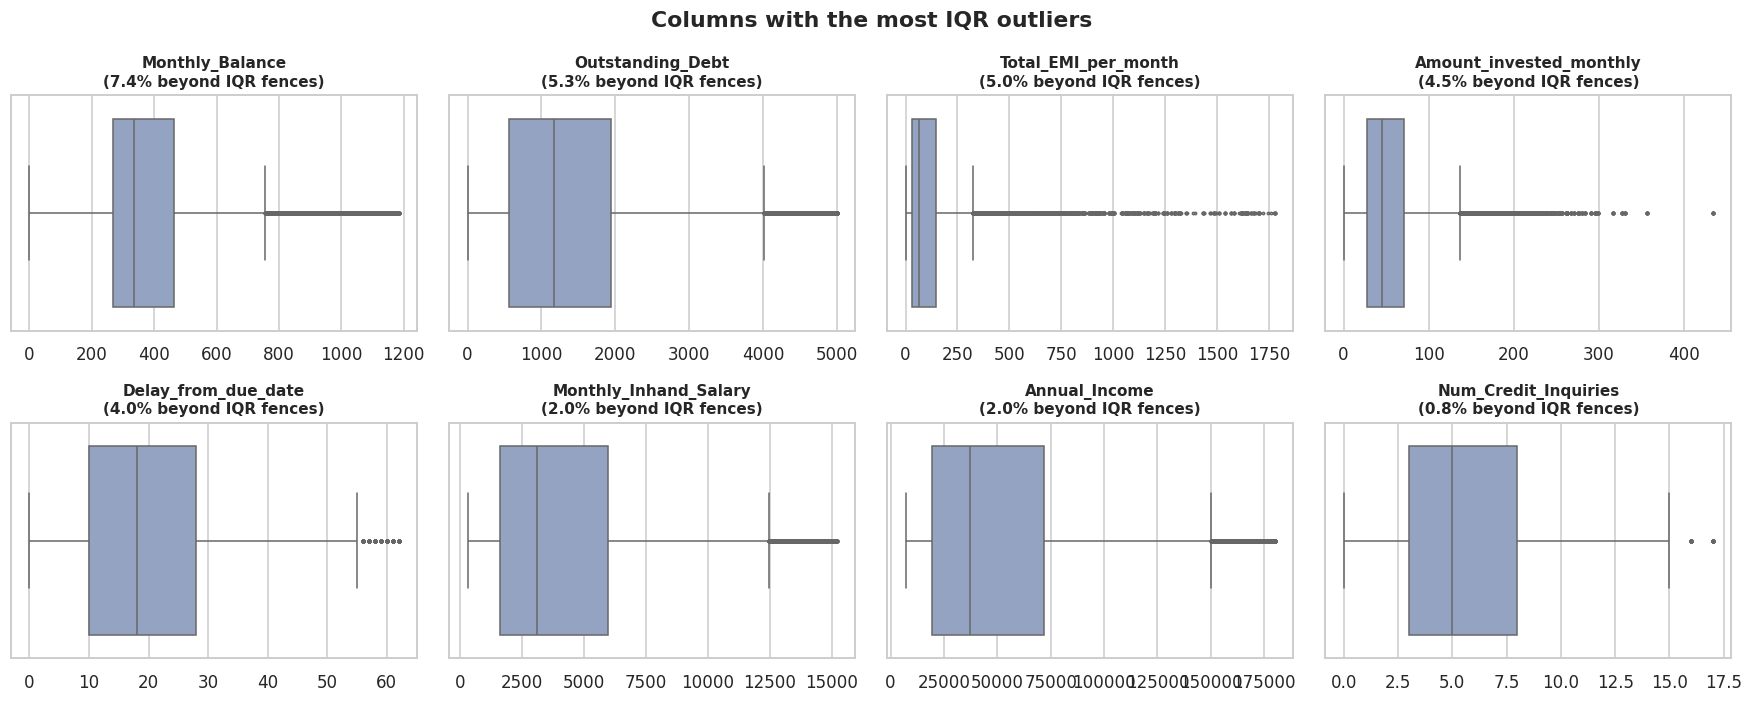

In [ ]:
# 5a. Statistical outlier scan (IQR rule) - detect first, then decide per variable
iqr_rows = []
for c in NUM_COLS:
    s = df[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_rows.append({"column": c, "lower_fence": lo, "upper_fence": hi,
                     "outliers": int(((s < lo) | (s > hi)).sum()),
                     "outlier_%": ((s < lo) | (s > hi)).mean() * 100, "max": s.max()})
iqr_table = pd.DataFrame(iqr_rows).set_index("column").sort_values("outlier_%", ascending=False)
display(iqr_table)

top_out = iqr_table.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, c in zip(axes.flat, top_out):
    sns.boxplot(x=df_copy[c], color="#8da0cb", ax=ax, fliersize=1.5)
    ax.set_title(f"{c}\n({iqr_table.loc[c, 'outlier_%']:.1f}% beyond IQR fences)", fontsize=10); ax.set_xlabel("")
plt.suptitle("Columns with the most IQR outliers", fontweight="bold")
plt.tight_layout(); plt.show()

**Outlier decision:** the IQR rule flags points far from the middle, but in financial data many of them are **real customers**
(high earners, large EMIs, big investments). They are therefore **kept**; charts use medians, log scales and rank-based tests
(Spearman, Kruskal-Wallis) that are robust to them. Only values that are **impossible** (outside the domain limits below) are
treated as errors and re-imputed.

In [ ]:
# 5. Outliers that are data-entry errors -> NaN (domain limits, not statistical trimming)
BOUNDS = {                      # (min, max) realistic values
    "Age": (14, 100),
    "Num_Bank_Accounts": (0, 20),
    "Num_Credit_Card": (0, 20),
    "Interest_Rate": (0, 40),
    "Num_of_Loan": (0, 15),
    "Num_of_Delayed_Payment": (0, 60),
    "Num_Credit_Inquiries": (0, 40),
    "Credit_Utilization_Ratio": (0, 100),
    "Outstanding_Debt": (0, None),
    "Annual_Income": (0, None),
    "Monthly_Inhand_Salary": (0, None),
    "Total_EMI_per_month": (0, None),
    "Amount_invested_monthly": (0, 9_999),   # 10,000 is a known placeholder value in this data
    "Monthly_Balance": (-1e5, 1e6),
}
outlier_report = {}
for c, (lo, hi) in BOUNDS.items():
    if c not in df_copy:
        continue
    bad = pd.Series(False, index=df_copy.index)
    if lo is not None: bad |= df_copy[c] < lo
    if hi is not None: bad |= df_copy[c] > hi
    outlier_report[c] = int(bad.sum())
    df_copy.loc[bad, c] = np.nan

# Income is a customer attribute: a month that is >2x the customer's own median income is an entry error
if "Customer_ID" in df_copy:
    for c in ["Annual_Income", "Monthly_Inhand_Salary"]:
        cust_med = df.groupby("Customer_ID")[c].transform("median")
        bad = df[c] > 2 * cust_med
        outlier_report[c] = outlier_report.get(c, 0) + int(bad.sum())
        df.loc[bad, c] = np.nan

display(pd.Series(outlier_report, name="invalid values set to NaN").to_frame().T)

,Age,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Num_of_Delayed_Payment,Num_Credit_Inquiries,Credit_Utilization_Ratio,Outstanding_Debt,Annual_Income,Monthly_Inhand_Salary,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance
invalid values set to NaN,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
# 6. Missing-value imputation - customer first, then global
def customer_mode(s):
    m = s.mode()
    return m.iloc[0] if len(m) else np.nan

STABLE = ["Age", "Occupation", "Annual_Income", "Monthly_Inhand_Salary", "Num_Bank_Accounts", "Num_Credit_Card",
          "Interest_Rate", "Num_of_Loan", "Type_of_Loan", "Credit_Mix", "Payment_Behaviour"]
VARYING = ["Num_of_Delayed_Payment", "Changed_Credit_Limit", "Num_Credit_Inquiries", "Outstanding_Debt",
           "Total_EMI_per_month", "Amount_invested_monthly", "Monthly_Balance", "Delay_from_due_date",
           "Credit_Utilization_Ratio"]
STABLE = [c for c in STABLE if c in df_copy]
VARYING = [c for c in VARYING if c in df_copy]

missing_before = df_copy.isna().sum()
has_cust = "Customer_ID" in df_copy
if has_cust:
    df_copy = df_copy.sort_values(["Customer_ID", "Month"]).reset_index(drop=True)
    g = df_copy.groupby("Customer_ID")
    for c in STABLE:
        if df_copy[c].isna().any():
            df_copy[c] = df_copy[c].fillna(df_copy["Customer_ID"].map(g[c].agg(customer_mode)))
    for c in VARYING:
        if df_copy[c].isna().any():
            df_copy[c] = df_copy[c].fillna(g[c].transform("median"))
    # credit history grows by one month each month -> interpolate inside each customer
    if df_copy["Credit_History_Age"].isna().any():
        df_copy["Credit_History_Age"] = g["Credit_History_Age"].transform(
            lambda s: s.interpolate(limit_direction="both"))

# global fallbacks
for c in df_copy.select_dtypes(include="number").columns:
    if c != "Month" and df_copy[c].isna().any():
        df_copy[c] = df_copy[c].fillna(df_copy[c].median())
fallback = {"Occupation": "Unknown", "Credit_Mix": "Unknown", "Payment_Behaviour": "Unknown",
            "Type_of_Loan": "No Loan Data", "Payment_of_Min_Amount": "Unknown"}
for c, v in fallback.items():
    if c in df_copy:
        df_copy[c] = df_copy[c].fillna(v)

# integer-valued columns back to int
for c in ["Age", "Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate", "Num_of_Loan",
          "Num_of_Delayed_Payment", "Num_Credit_Inquiries", "Delay_from_due_date"]:
    if c in df_copy:
        df_copy[c] = df_copy[c].round().astype(int)

summary = pd.DataFrame({"missing_before": missing_before, "missing_after": df_copy.isna().sum()})
display(summary[summary.missing_before > 0])

,missing_before,missing_after


In [ ]:
# 7. Target encoding + analysis bands
df_copy["Credit_Score"] = df_copy["Credit_Score"].astype(str).str.strip().str.title()
df_copy = df_copy[df_copy["Credit_Score"].isin(SCORE_ORDER)].copy()
df_copy["Credit_Score"] = pd.Categorical(df_copy["Credit_Score"], categories=SCORE_ORDER, ordered=True)
df_copy["Credit_Score_Num"] = df_copy["Credit_Score"].map(SCORE_MAP).astype(int)

AGE_LABELS = ["14-24", "25-34", "35-44", "45+"]
df_copy["Age_Group"] = pd.cut(df_copy["Age"], bins=[0, 24, 34, 44, 200], labels=AGE_LABELS)
df_copy["Income_Quintile"] = pd.qcut(df_copy["Annual_Income"], 5,
                                labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
df_copy["Utilization_Band"] = pd.cut(df_copy["Credit_Utilization_Ratio"], bins=[0, 25, 30, 35, 40, 100],
                                labels=["<25%", "25-30%", "30-35%", "35-40%", "40%+"], include_lowest=True)
df_copy["Delayed_Bucket"] = pd.cut(df_copy["Num_of_Delayed_Payment"], bins=[-1, 0, 5, 10, 15, 20, 1000],
                              labels=["0", "1-5", "6-10", "11-15", "16-20", "21+"])
df_copy["Debt_to_Income"] = df_copy["Outstanding_Debt"] / df_copy["Annual_Income"].replace(0, np.nan)

print(f"Clean dataset: {df_copy.shape[0]:,} rows x {df_copy.shape[1]} columns, remaining nulls: {int(df_copy.isna().sum().sum())}")
df_copy.head()

Clean dataset: 100,000 rows x 33 columns, remaining nulls: 0


,ID,Customer_ID,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,Month_Name,Credit_Score_Num,Age_Group,Income_Quintile,Utilization_Band,Delayed_Bucket,Debt_to_Income
0,27750,1006,1,37,Journalist,"16,756.18","1,331.35",9,6,22,2,"Credit-Builder Loan, and Payday Loan",48,10,10.66,8,Standard,"1,941.73",37.50,182.00,Yes,27.44,45.30,High_spent_Medium_value_payments,310.39,Poor,Jan,0,35-44,Q1 (lowest),35-40%,6-10,0.12
1,27751,1006,2,38,Journalist,"16,756.18","1,331.35",9,6,22,2,"Credit-Builder Loan, and Payday Loan",48,12,10.66,8,Standard,"1,941.73",34.71,183.00,Yes,27.44,45.30,Low_spent_Medium_value_payments,295.61,Poor,Feb,0,35-44,Q1 (lowest),30-35%,11-15,0.12
2,27752,1006,3,38,Journalist,"16,756.18","1,331.35",9,6,22,2,"Credit-Builder Loan, and Payday Loan",48,12,10.66,8,Standard,"1,941.73",32.19,184.00,Yes,27.44,45.30,Low_spent_Small_value_payments,333.96,Poor,Mar,0,35-44,Q1 (lowest),30-35%,11-15,0.12
3,27753,1006,4,38,Journalist,"16,756.18","1,331.35",9,6,22,2,"Credit-Builder Loan, and Payday Loan",48,13,10.66,8,Standard,"1,941.73",33.73,185.00,Yes,27.44,45.30,High_spent_Small_value_payments,309.20,Poor,Apr,0,35-44,Q1 (lowest),30-35%,11-15,0.12
4,27754,1006,5,38,Journalist,"16,756.18","1,331.35",9,6,22,2,"Credit-Builder Loan, and Payday Loan",48,12,10.66,8,Standard,"1,941.73",38.76,186.00,Yes,27.44,45.30,Low_spent_Large_value_payments,323.97,Poor,May,0,35-44,Q1 (lowest),35-40%,11-15,0.12


In [ ]:
# Sanity checks - the analysis below relies on these being true
assert df_copy["Credit_Score"].notna().all(), "unmapped target values"
assert df_copy[NUM_COLS].isna().sum().sum() == 0, "numeric nulls remain"
assert df_copy["Age"].between(14, 100).all(), "age out of range"
assert df_copy["Num_Credit_Card"].between(0, 20).all(), "card count out of range"
print("All data-quality checks passed")

All data-quality checks passed


### What all manipulations have you done and insights you found?

In [ ]:
lines = [f"- **{name}:** {n:,}" for name, n in log]
n_invalid, n_filled = sum(outlier_report.values()), int(missing_before.sum())
lines += [(f"- **Impossible values set to NaN and re-imputed:** {n_invalid:,} "
           f"(largest: {', '.join(f'{k} {v:,}' for k, v in sorted(outlier_report.items(), key=lambda x: -x[1])[:3] if v)})")
          if n_invalid else "- **Impossible values:** none - every column is within its realistic domain range.",
          (f"- **Missing values filled:** {n_filled:,} cells, first from the same customer's other months, which keeps each "
           "customer internally consistent instead of injecting a population average.")
          if n_filled else "- **Missing values:** none, so no imputation was needed (the customer-level imputation logic is kept so the notebook also handles the raw version of this data).",
          f"- **IQR scan:** {int((iqr_table['outliers'] > 0).sum())} columns have points beyond the 1.5×IQR fences "
          f"(most: {', '.join(f'{c} {p:.1f}%' for c, p in iqr_table['outlier_%'].head(3).items())}). Values inside realistic domain limits were kept; impossible ones were handled by the domain-limit step.",
          "- **Dropped:** Name and SSN (personal identifiers). **Added:** Credit_Score_Num, Month_Name, Age_Group, Income_Quintile, Utilization_Band, Delayed_Bucket, Debt_to_Income.",
          "- Heavy-tailed but genuine variables (income, debt) were **not trimmed**; charts use log scales or medians instead.",
          f"- Because each customer appears once per month, statistical tests on {len(df_copy):,} rows give tiny p-values for almost any "
          "difference. Conclusions therefore rely on **effect size** (Spearman ρ, ε², Cramér's V), not on p-values alone."]
display(Markdown("\n".join(lines)))

- **Duplicate rows removed:** 0
- **PII columns dropped:** 2
- **Placeholder strings converted to NaN:** 0
- **Numbers stored as text repaired (e.g. '45_'):** 0
- **Impossible values:** none - every column is within its realistic domain range.
- **Missing values:** none, so no imputation was needed (the customer-level imputation logic is kept so the notebook also handles the raw version of this data).
- **IQR scan:** 10 columns have points beyond the 1.5×IQR fences (most: Monthly_Balance 7.4%, Outstanding_Debt 5.3%, Total_EMI_per_month 5.0%). Values inside realistic domain limits were kept; impossible ones were handled by the domain-limit step.
- **Dropped:** Name and SSN (personal identifiers). **Added:** Credit_Score_Num, Month_Name, Age_Group, Income_Quintile, Utilization_Band, Delayed_Bucket, Debt_to_Income.
- Heavy-tailed but genuine variables (income, debt) were **not trimmed**; charts use log scales or medians instead.
- Because each customer appears once per month, statistical tests on 100,000 rows give tiny p-values for almost any difference. Conclusions therefore rely on **effect size** (Spearman ρ, ε², Cramér's V), not on p-values alone.

## ***4. Data Visualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

The analysis flows **univariate → bivariate → multivariate**:
- **Univariate** (Charts 1-5) – understand each variable on its own: shape, skew, imbalance, data quality left after cleaning.
- **Bivariate** (Charts 6-14) – test each hypothesis and visualization question against the credit score.
- **Multivariate** (Charts 15-17) – check how drivers interact and whether one explains another.

In [ ]:
# Shared statistical helpers
def strength(r):
    a = abs(r)
    return "negligible" if a < 0.1 else "weak" if a < 0.3 else "moderate" if a < 0.5 else "strong"

def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

def spearman_vs_score(col, data=None):
    d = (df_copy if data is None else data)[[col, "Credit_Score_Num"]].dropna()
    rho, p = stats.spearmanr(d[col], d["Credit_Score_Num"])
    return rho, p, len(d)

def kruskal_by_score(col, data=None):
    d = df_copy if data is None else data
    groups = [d.loc[d["Credit_Score"] == s, col].dropna() for s in SCORE_ORDER]
    groups = [g for g in groups if len(g)]
    H, p = stats.kruskal(*groups)
    n, k = sum(len(g) for g in groups), len(groups)
    return H, p, max(0.0, (H - k + 1) / (n - k))       # epsilon-squared effect size

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    return v, p, chi2, dof

def score_shares(by):
    return pd.crosstab(df[by], df["Credit_Score"], normalize="index").reindex(columns=SCORE_ORDER) * 100

HYPOTHESES = []
def record(hid, question, evidence, verdict):
    HYPOTHESES.append({"ID": hid, "Question": question, "Evidence": evidence, "Verdict": verdict})

def verdict_from_rho(rho, p, expected_sign):
    if p >= 0.05 or abs(rho) < 0.1:
        return f"Not supported - relationship is negligible (ρ = {rho:+.2f})"
    direction = "positive" if rho > 0 else "negative"
    if np.sign(rho) == expected_sign:
        return f"Supported - {strength(rho)} {direction} relationship (ρ = {rho:+.2f})"
    return f"Rejected - the relationship is {strength(rho)} and {direction} (ρ = {rho:+.2f}), opposite to the assumption"

def show(text):
    display(Markdown(text))

### **Univariate analysis**

#### Chart - 1 : Credit score distribution (target)

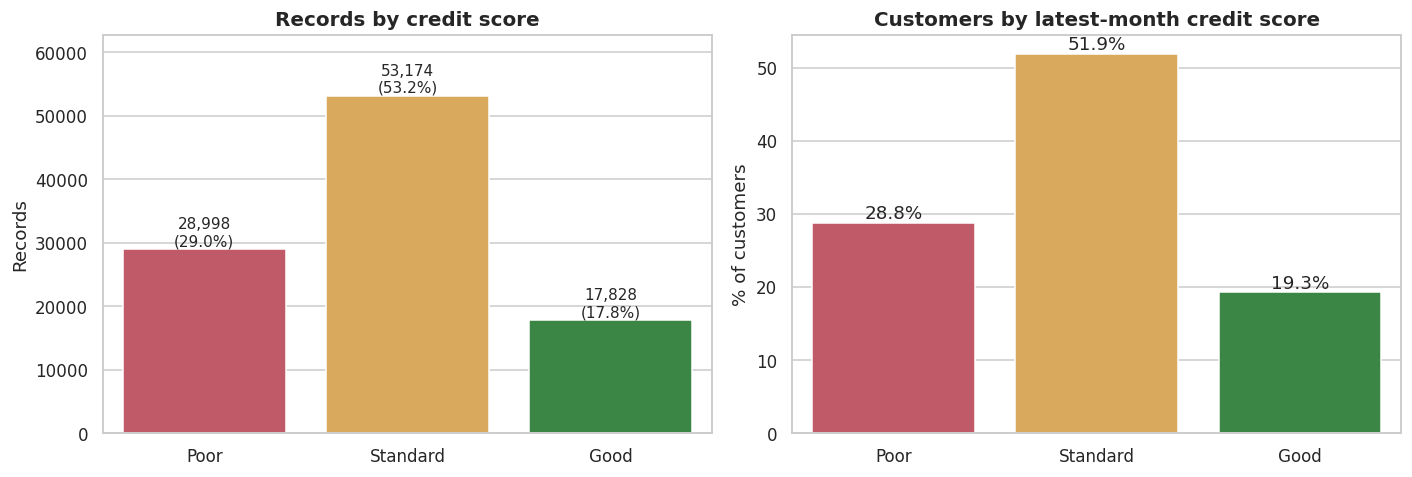

In [ ]:
counts = df_copy["Credit_Score"].value_counts().reindex(SCORE_ORDER)
shares = counts / counts.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=counts.index, y=counts.values, palette=PALETTE, ax=axes[0])
for i, (c, s) in enumerate(zip(counts, shares)):
    axes[0].text(i, c, f"{c:,}\n({s:.1f}%)", ha="center", va="bottom", fontsize=10)
axes[0].set(title="Records by credit score", xlabel="", ylabel="Records")
axes[0].set_ylim(0, counts.max() * 1.18)

# customer view: each customer's most recent month
if "Customer_ID" in df:
    latest = df.sort_values("Month").groupby("Customer_ID").tail(1)
    cust = latest["Credit_Score"].value_counts(normalize=True).reindex(SCORE_ORDER) * 100
    sns.barplot(x=cust.index, y=cust.values, palette=PALETTE, ax=axes[1])
    for i, v in enumerate(cust):
        axes[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom")
    axes[1].set(title="Customers by latest-month credit score", xlabel="", ylabel="% of customers")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A bar chart is the clearest way to compare the size of a few categories. The target is checked first because every later comparison is read relative to these baseline shares, and class imbalance changes how a future model must be trained. The second panel counts each customer once (latest month) so repeated monthly rows do not distort the picture.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
major, minor = shares.idxmax(), shares.idxmin()
show(f"""
**Insight:** {major} is the most common class ({shares[major]:.1f}% of records) and {minor} the least common ({shares[minor]:.1f}%).
Poor = {shares['Poor']:.1f}%, Standard = {shares['Standard']:.1f}%, Good = {shares['Good']:.1f}%. The classes are
{'clearly imbalanced' if shares.max() / shares.min() > 1.8 else 'reasonably balanced'} (largest/smallest = {shares.max() / shares.min():.1f}x).

**Business impact:** Roughly {shares['Poor']:.0f}% of the base is high-risk (Poor) while only {shares['Good']:.0f}% qualifies
for premium products. The large middle (Standard) is the main growth opportunity: moving Standard customers to Good widens the
pool for low-risk lending. *Negative signal:* any model built later must handle the imbalance (class weights / stratified splits),
otherwise it will under-detect the {minor} class.
""")


**Insight:** Standard is the most common class (53.2% of records) and Good the least common (17.8%).
Poor = 29.0%, Standard = 53.2%, Good = 17.8%. The classes are
clearly imbalanced (largest/smallest = 3.0x).

**Business impact:** Roughly 29% of the base is high-risk (Poor) while only 18% qualifies
for premium products. The large middle (Standard) is the main growth opportunity: moving Standard customers to Good widens the
pool for low-risk lending. *Negative signal:* any model built later must handle the imbalance (class weights / stratified splits),
otherwise it will under-detect the Good class.


#### Chart - 2 : Age distribution

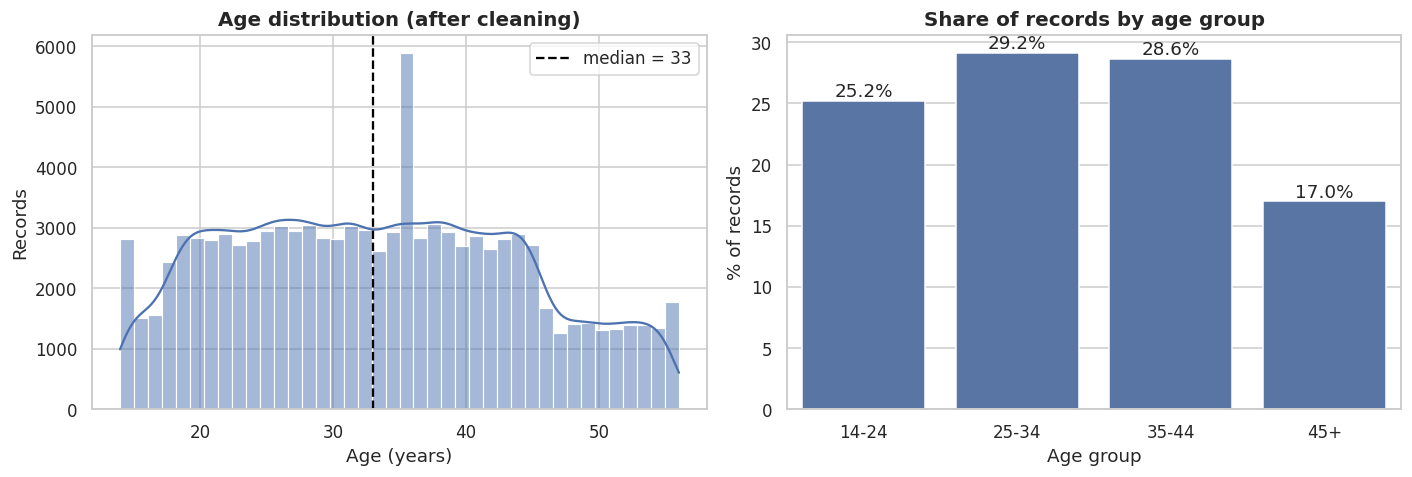

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df_copy["Age"], bins=40, kde=True, color="#4c72b0", ax=axes[0])
axes[0].axvline(df_copy["Age"].median(), color="black", ls="--", label=f"median = {df_copy['Age'].median():.0f}")
axes[0].set(title="Age distribution (after cleaning)", xlabel="Age (years)", ylabel="Records"); axes[0].legend()
ag = df_copy["Age_Group"].value_counts(normalize=True).reindex(AGE_LABELS) * 100
sns.barplot(x=ag.index, y=ag.values, color="#4c72b0", ax=axes[1])
for i, v in enumerate(ag): axes[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom")
axes[1].set(title="Share of records by age group", xlabel="Age group", ylabel="% of records")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A histogram with a KDE line shows the shape of a continuous variable and confirms the cleaning worked (no impossible ages). The age-group bar chart introduces the bands used later for V1.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
show(f"""
**Insight:** After cleaning, ages range from {df_copy['Age'].min()} to {df_copy['Age'].max()} (median {df_copy['Age'].median():.0f}).
The largest band is **{ag.idxmax()}** ({ag.max():.1f}% of records); the smallest is **{ag.idxmin()}** ({ag.min():.1f}%).

**Business impact:** The customer base is concentrated in working-age adults, so product design and marketing should target
that range. The small {ag.idxmin()} segment means conclusions about it carry more uncertainty.
""")


**Insight:** After cleaning, ages range from 14 to 56 (median 33).
The largest band is **25-34** (29.2% of records); the smallest is **45+** (17.0%).

**Business impact:** The customer base is concentrated in working-age adults, so product design and marketing should target
that range. The small 45+ segment means conclusions about it carry more uncertainty.


#### Chart - 3 : Annual income distribution

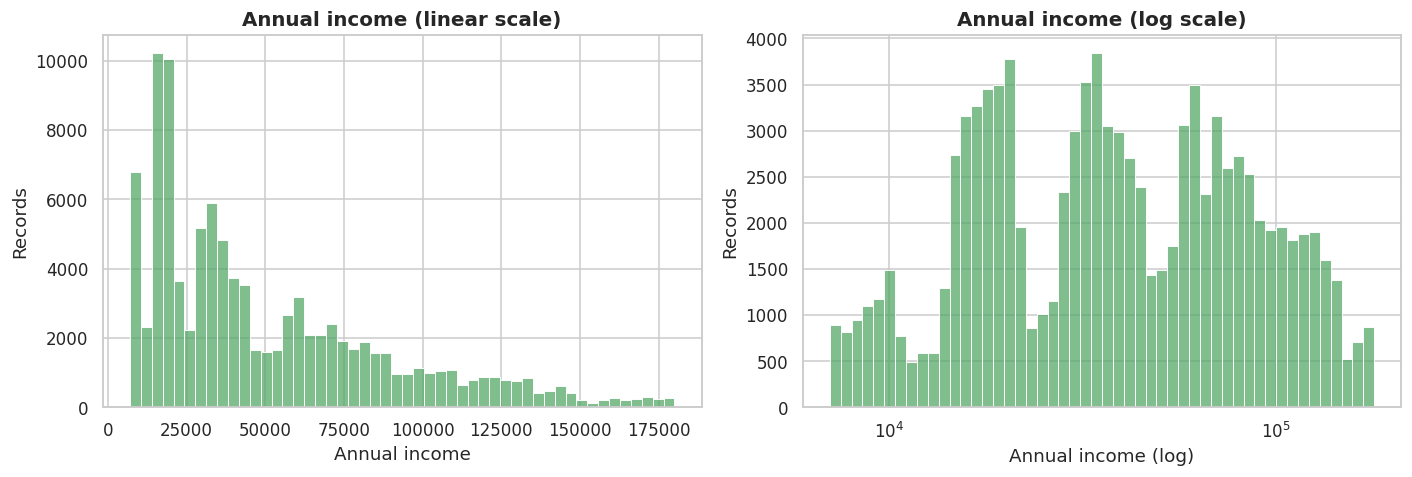

                   count      mean       std      min       25%       50%  \
Annual_Income 100,000.00 50,505.12 38,299.42 7,005.93 19,342.97 36,999.71   

                    75%        95%        max  
Annual_Income 71,683.47 130,289.65 179,987.28  


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df_copy["Annual_Income"], bins=50, color="#55a868", ax=axes[0])
axes[0].set(title="Annual income (linear scale)", xlabel="Annual income", ylabel="Records")
sns.histplot(df_copy["Annual_Income"], bins=50, log_scale=True, color="#55a868", ax=axes[1])
axes[1].set(title="Annual income (log scale)", xlabel="Annual income (log)", ylabel="Records")
plt.tight_layout(); plt.show()
print(df_copy["Annual_Income"].describe(percentiles=[.25, .5, .75, .95]).to_frame().T)

##### 1. Why did you pick the specific chart?

Income is money, so it is usually right-skewed. Showing linear and log scales side by side proves the skew and justifies why later income charts use a log axis and medians instead of means.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
inc = df_copy["Annual_Income"]
show(f"""
**Insight:** Income is strongly right-skewed (skewness = {inc.skew():.2f}); the mean ({inc.mean():,.0f}) is
{inc.mean() / inc.median():.2f}x the median ({inc.median():,.0f}). The top 5% earn above {inc.quantile(.95):,.0f}.
On a log scale the distribution is close to bell-shaped, which is typical of income data.

**Business impact:** Using the median avoids over-estimating a "typical" customer's repayment capacity. High earners are real
customers (not errors) and were kept – they are prime candidates for premium cards and larger loans.
""")


**Insight:** Income is strongly right-skewed (skewness = 1.13); the mean (50,505) is
1.37x the median (37,000). The top 5% earn above 130,290.
On a log scale the distribution is close to bell-shaped, which is typical of income data.

**Business impact:** Using the median avoids over-estimating a "typical" customer's repayment capacity. High earners are real
customers (not errors) and were kept – they are prime candidates for premium cards and larger loans.


#### Chart - 4 : Distribution of key numeric credit variables

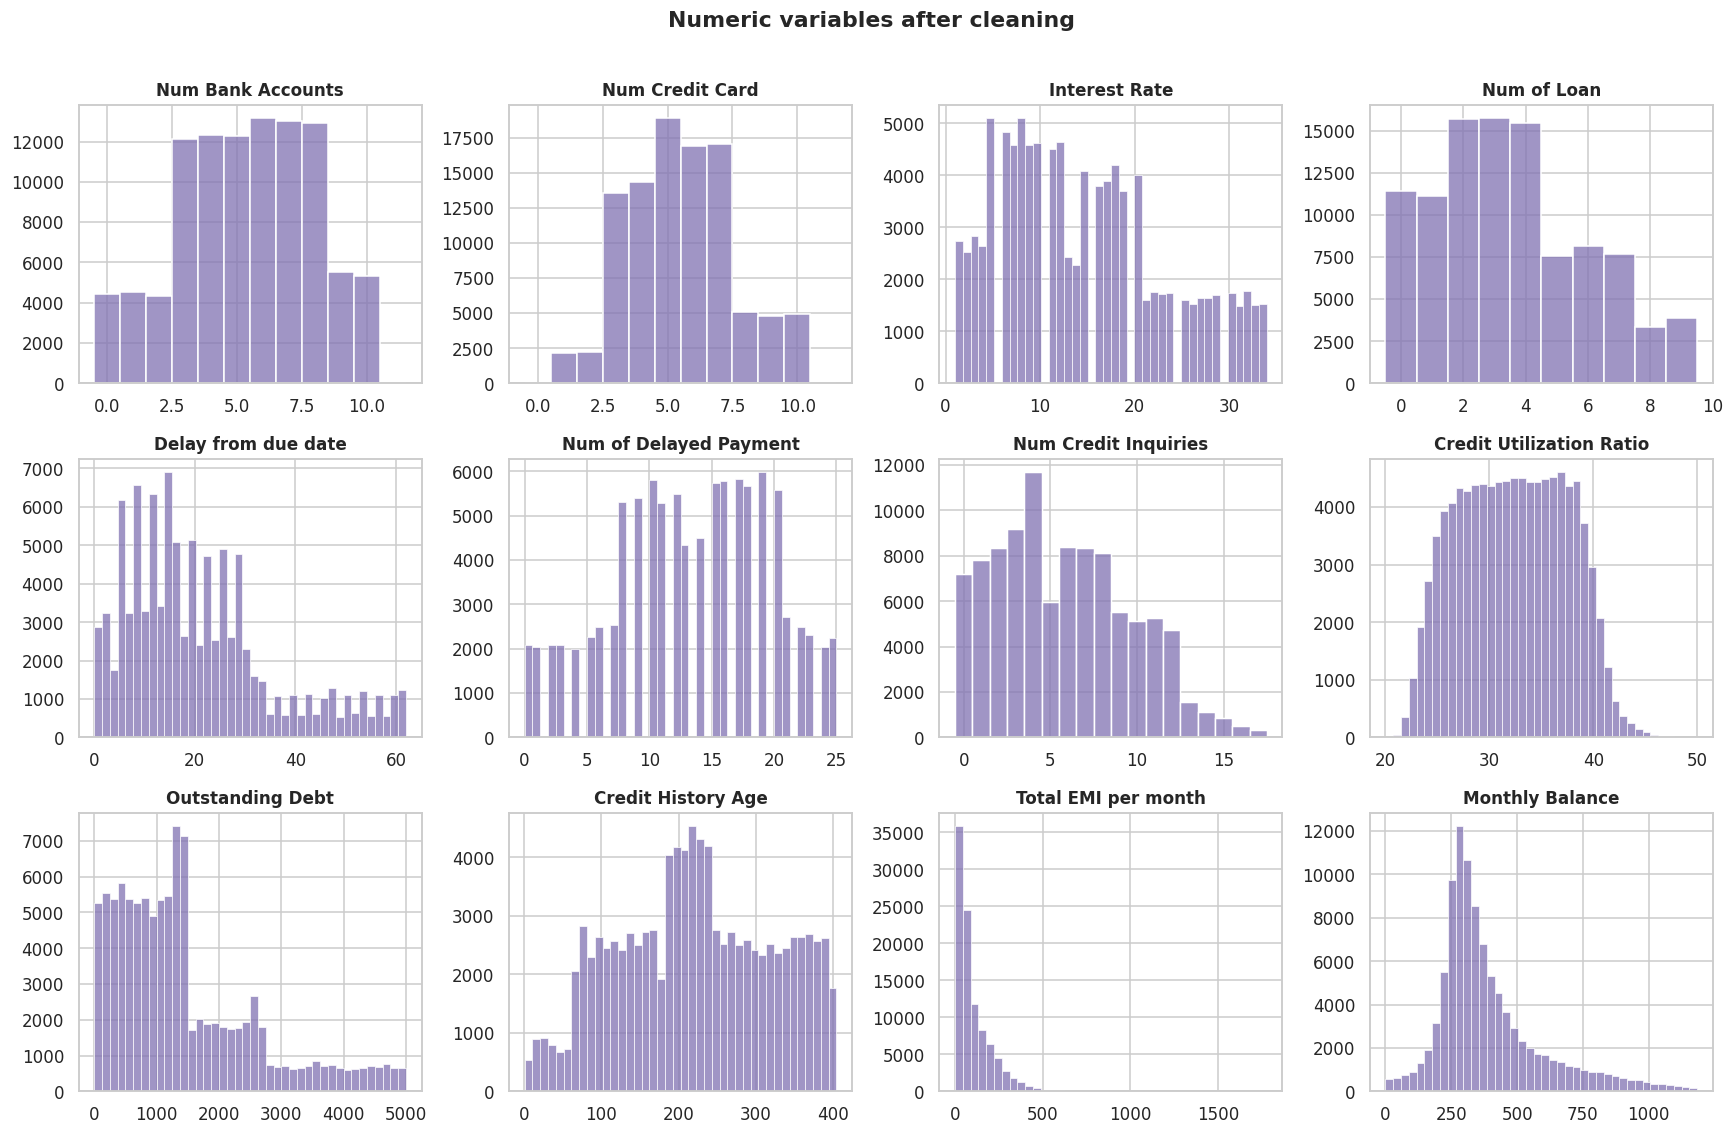

In [ ]:
num_view = ["Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate", "Num_of_Loan", "Delay_from_due_date",
            "Num_of_Delayed_Payment", "Num_Credit_Inquiries", "Credit_Utilization_Ratio", "Outstanding_Debt",
            "Credit_History_Age", "Total_EMI_per_month", "Monthly_Balance"]
num_view = [c for c in num_view if c in df_copy]
ncols = 4; nrows = int(np.ceil(len(num_view) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.4 * nrows))
for ax, c in zip(axes.flat, num_view):
    discrete = df_copy[c].nunique() <= 25
    sns.histplot(df_copy[c], bins=None if discrete else 40, discrete=discrete, color="#8172b2", ax=ax)
    ax.set_title(c.replace("_", " "), fontsize=11); ax.set_xlabel(""); ax.set_ylabel("")
for ax in list(axes.flat)[len(num_view):]: ax.remove()
plt.suptitle("Numeric variables after cleaning", fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A small-multiples grid of histograms lets every numeric feature be checked in one view: skew, spikes, remaining outliers and whether a variable is discrete (counts) or continuous.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
sk = df_copy[num_view].skew().sort_values(ascending=False)
show(f"""
**Insight:** Most skewed variables: {', '.join(f'**{k}** ({v:.1f})' for k, v in sk.head(3).items())}.
Count variables (cards, loans, accounts, inquiries) all sit in realistic ranges, so no impossible values remain.
Credit utilization ranges {df_copy['Credit_Utilization_Ratio'].min():.0f}%–{df_copy['Credit_Utilization_Ratio'].max():.0f}% (median {df_copy['Credit_Utilization_Ratio'].median():.1f}%).
Median delay from due date is {df_copy['Delay_from_due_date'].median():.0f} days and median delayed payments is {df_copy['Num_of_Delayed_Payment'].median():.0f}.

**Business impact:** Late payment is common, not rare, in this base – which makes payment behaviour a key lever for advisory
products. Skewed variables (debt, EMI) should be compared with medians or rank-based tests, which is what the rest of this notebook does.
""")


**Insight:** Most skewed variables: **Total_EMI_per_month** (4.0), **Monthly_Balance** (1.4), **Outstanding_Debt** (1.2).
Count variables (cards, loans, accounts, inquiries) all sit in realistic ranges, so no impossible values remain.
Credit utilization ranges 20%–50% (median 32.3%).
Median delay from due date is 18 days and median delayed payments is 14.

**Business impact:** Late payment is common, not rare, in this base – which makes payment behaviour a key lever for advisory
products. Skewed variables (debt, EMI) should be compared with medians or rank-based tests, which is what the rest of this notebook does.


#### Chart - 5 : Categorical variables

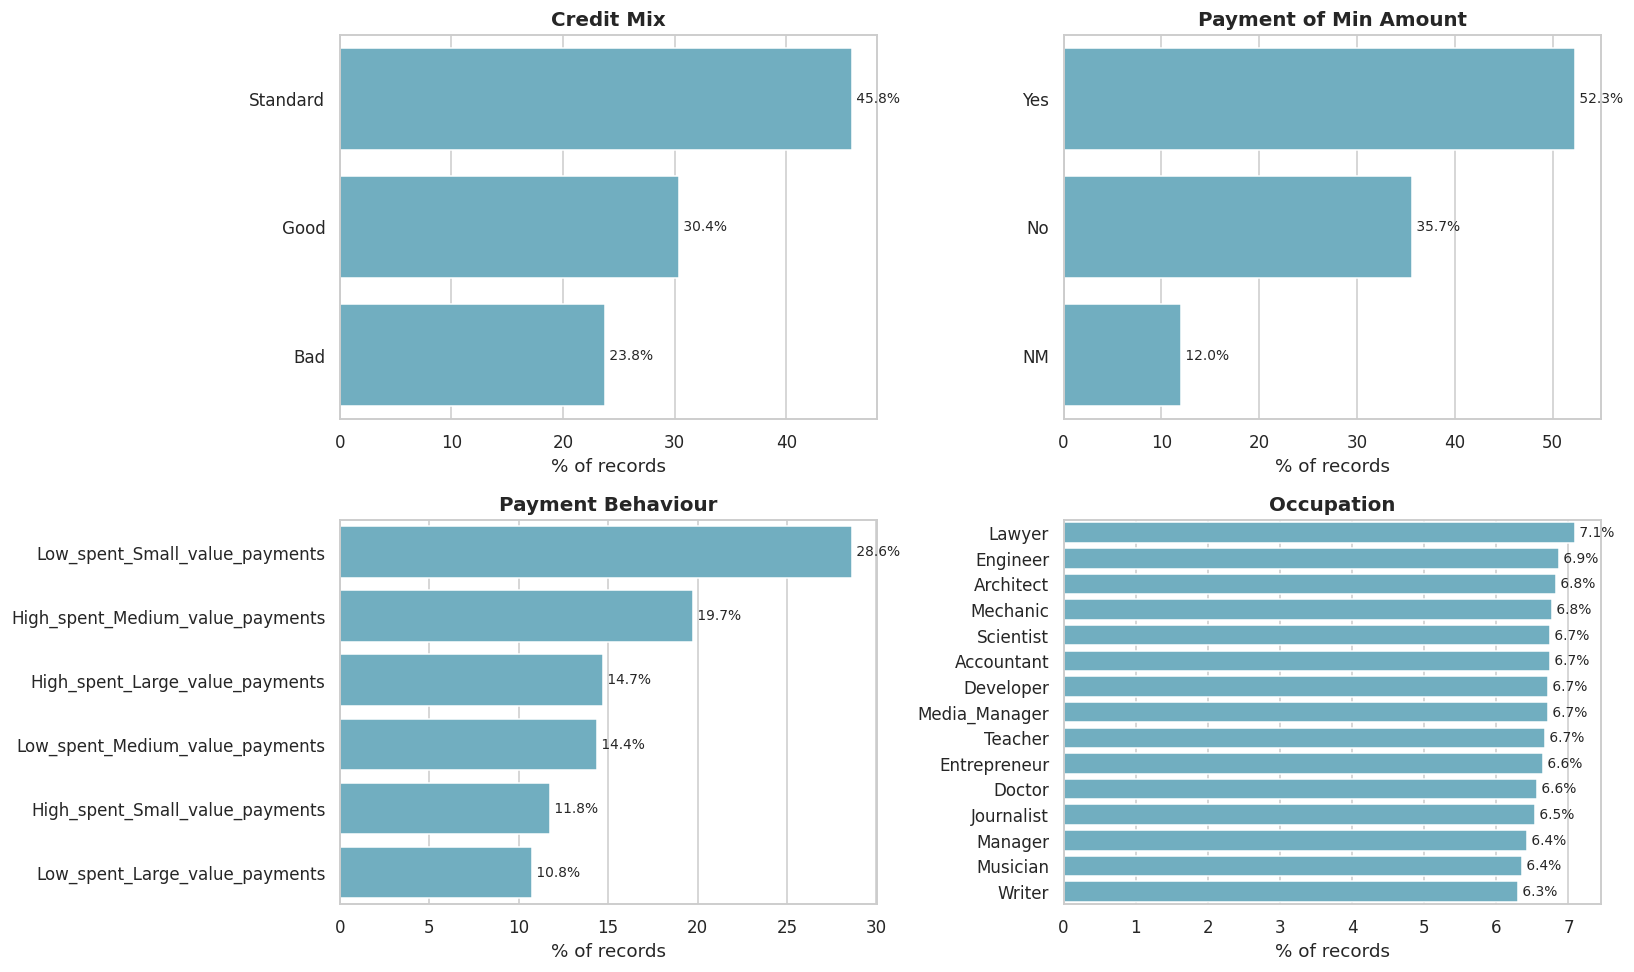

In [ ]:
cat_view = [c for c in ["Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour", "Occupation"] if c in df_copy]
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, c in zip(axes.flat, cat_view):
    vc = df_copy[c].value_counts(normalize=True) * 100
    sns.barplot(y=vc.index.astype(str), x=vc.values, color="#64b5cd", ax=ax)
    for i, v in enumerate(vc.values): ax.text(v, i, f" {v:.1f}%", va="center", fontsize=9)
    ax.set(title=c.replace("_", " "), xlabel="% of records", ylabel="")
for ax in list(axes.flat)[len(cat_view):]: ax.remove()
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

Horizontal bars keep long category labels (occupations, payment behaviours) readable and make shares easy to compare.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
pm = df_copy["Payment_of_Min_Amount"].value_counts(normalize=True) * 100 if "Payment_of_Min_Amount" in df_copy else pd.Series(dtype=float)
cm = df_copy["Credit_Mix"].value_counts(normalize=True) * 100
show(f"""
**Insight:** Credit mix: {', '.join(f'{k} {v:.1f}%' for k, v in cm.items())}.
{'Paying only the minimum amount ("Yes") applies to ' + f"{pm.get('Yes', 0):.1f}% of records." if len(pm) else ''}
Occupations are spread evenly ({df_copy['Occupation'].nunique()} groups), so occupation alone is unlikely to explain credit score.

**Business impact:** Customers who only pay the minimum are accumulating interest and are natural targets for debt-consolidation
or balance-transfer offers. The even occupation spread means Paisabazaar should not use occupation as a shortcut for risk.
""")


**Insight:** Credit mix: Standard 45.8%, Good 30.4%, Bad 23.8%.
Paying only the minimum amount ("Yes") applies to 52.3% of records.
Occupations are spread evenly (15 groups), so occupation alone is unlikely to explain credit score.

**Business impact:** Customers who only pay the minimum are accumulating interest and are natural targets for debt-consolidation
or balance-transfer offers. The even occupation spread means Paisabazaar should not use occupation as a shortcut for risk.


### **Bivariate analysis – testing the assumptions**

#### Chart - 6 : H1 – Does higher annual income correlate with a higher credit score?

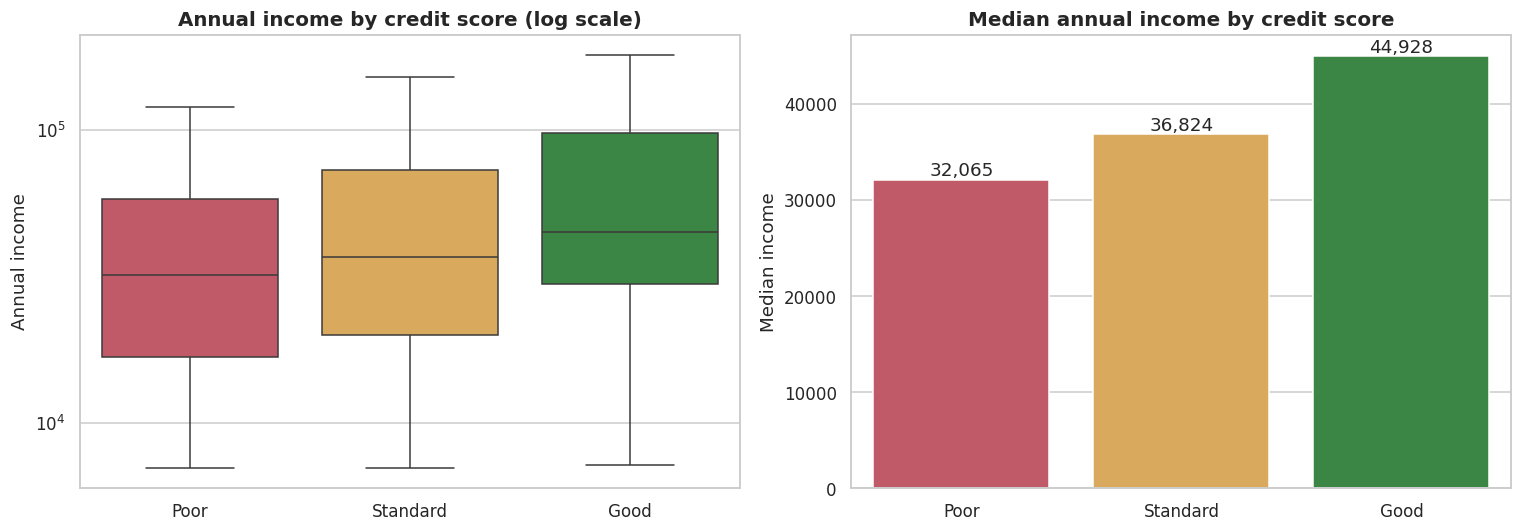

Spearman rho = +0.207 (p < 0.001) | Kruskal-Wallis H = 4,344 (p < 0.001), effect size eps^2 = 0.043


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df_copy, x="Credit_Score", y="Annual_Income", order=SCORE_ORDER, palette=PALETTE,
            showfliers=False, ax=axes[0])
axes[0].set_yscale("log"); axes[0].set(title="Annual income by credit score (log scale)", xlabel="", ylabel="Annual income")
med_inc = df_copy.groupby("Credit_Score", observed=True)["Annual_Income"].median().reindex(SCORE_ORDER)
sns.barplot(x=med_inc.index, y=med_inc.values, palette=PALETTE, ax=axes[1])
for i, v in enumerate(med_inc): axes[1].text(i, v, f"{v:,.0f}", ha="center", va="bottom")
axes[1].set(title="Median annual income by credit score", xlabel="", ylabel="Median income")
plt.tight_layout(); plt.show()

rho1, p1, n1 = spearman_vs_score("Annual_Income")
H1s, pH1, eps1 = kruskal_by_score("Annual_Income")
print(f"Spearman rho = {rho1:+.3f} (p {fmt_p(p1)}) | Kruskal-Wallis H = {H1s:,.0f} (p {fmt_p(pH1)}), effect size eps^2 = {eps1:.3f}")
v1 = verdict_from_rho(rho1, p1, +1)
record("H1", "Higher annual income -> higher credit score?", f"Spearman ρ = {rho1:+.2f}; ε² = {eps1:.3f}", v1)

##### 1. Why did you pick the specific chart?

A box plot compares the full income distribution of each score class (median, spread), and the log axis handles the skew seen in Chart 3. The median bar chart gives one easy-to-read number per class. Spearman correlation is used because the score is ordinal (Poor < Standard < Good) and income is skewed.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
show(f"""
**Verdict for H1: {v1}.**

**Insight:** Median income is {med_inc['Poor']:,.0f} for Poor, {med_inc['Standard']:,.0f} for Standard and {med_inc['Good']:,.0f}
for Good customers – Good-score customers earn {med_inc['Good'] / med_inc['Poor']:.2f}x the Poor group's median. The boxes still overlap
heavily, so income {'helps but does not decide' if abs(rho1) < 0.3 else 'is an important part of'} the score.

**Business impact:** Income {'should be one input, not the gatekeeper,' if abs(rho1) < 0.3 else 'is a useful screening signal'} in credit
assessment. Rejecting low-income applicants by default would turn away many creditworthy customers (negative growth), while
approving on income alone would miss high earners with poor repayment behaviour.
""")


**Verdict for H1: Supported - weak positive relationship (ρ = +0.21).**

**Insight:** Median income is 32,065 for Poor, 36,824 for Standard and 44,928
for Good customers – Good-score customers earn 1.40x the Poor group's median. The boxes still overlap
heavily, so income helps but does not decide the score.

**Business impact:** Income should be one input, not the gatekeeper, in credit
assessment. Rejecting low-income applicants by default would turn away many creditworthy customers (negative growth), while
approving on income alone would miss high earners with poor repayment behaviour.


#### Chart - 7 : V2 – How does annual income vary with credit score ranges? (interactive)

In [ ]:
def score_shares(by):
    return pd.crosstab(df_copy[by], df_copy["Credit_Score"], normalize="index").reindex(columns=SCORE_ORDER) * 100

In [ ]:
iq = score_shares("Income_Quintile").reset_index().melt(id_vars="Income_Quintile", var_name="Credit_Score", value_name="Share")
fig = px.bar(iq, x="Income_Quintile", y="Share", color="Credit_Score", color_discrete_map=PALETTE,
             category_orders={"Credit_Score": SCORE_ORDER}, text=iq["Share"].round(1),
             title="Credit score mix within each income quintile",
             labels={"Income_Quintile": "Annual income quintile (20% of customers each)", "Share": "% of records"})
fig.update_layout(barmode="stack", yaxis_ticksuffix="%", legend_title_text="Credit score")
fig.show()

q_rng = df_copy.groupby("Income_Quintile", observed=True)["Annual_Income"].agg(["min", "max"])
display(q_rng.style.format("{:,.0f}").set_caption("Income range per quintile"))

,min,max
Income_Quintile,,
Q1 (lowest),"7,006","17,592"
Q2,"17,594","30,989"
Q3,"30,989","48,435"
Q4,"48,495","81,050"
Q5 (highest),"81,067","179,987"


##### 1. Why did you pick the specific chart?

A 100 % stacked bar answers 'how does the score mix change as income rises' directly: each income quintile holds the same number of customers, so differences in colour proportions are fair to compare. Plotly makes it interactive (hover for exact %), which is useful in a presentation.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
sq = score_shares("Income_Quintile")
show(f"""
**Insight:** In the lowest income quintile {sq['Good'].iloc[0]:.1f}% of records are Good and {sq['Poor'].iloc[0]:.1f}% Poor;
in the highest quintile {sq['Good'].iloc[-1]:.1f}% are Good and {sq['Poor'].iloc[-1]:.1f}% Poor.
The share of Good scores changes by {sq['Good'].iloc[-1] - sq['Good'].iloc[0]:+.1f} percentage points from bottom to top quintile.

**Business impact:** This gives Paisabazaar an income-band view of risk that is easy to use in product rules – e.g. which
income bands to target with premium cards. Every quintile still contains Good and Poor customers, so income bands must be
combined with behavioural data (Charts 8-10) before a decision is made.
""")


**Insight:** In the lowest income quintile 8.8% of records are Good and 41.3% Poor;
in the highest quintile 30.4% are Good and 14.2% Poor.
The share of Good scores changes by +21.6 percentage points from bottom to top quintile.

**Business impact:** This gives Paisabazaar an income-band view of risk that is easy to use in product rules – e.g. which
income bands to target with premium cards. Every quintile still contains Good and Poor customers, so income bands must be
combined with behavioural data (Charts 8-10) before a decision is made.


#### Chart - 8 : H2 – Does credit utilization have a greater impact on credit score than the number of loans?

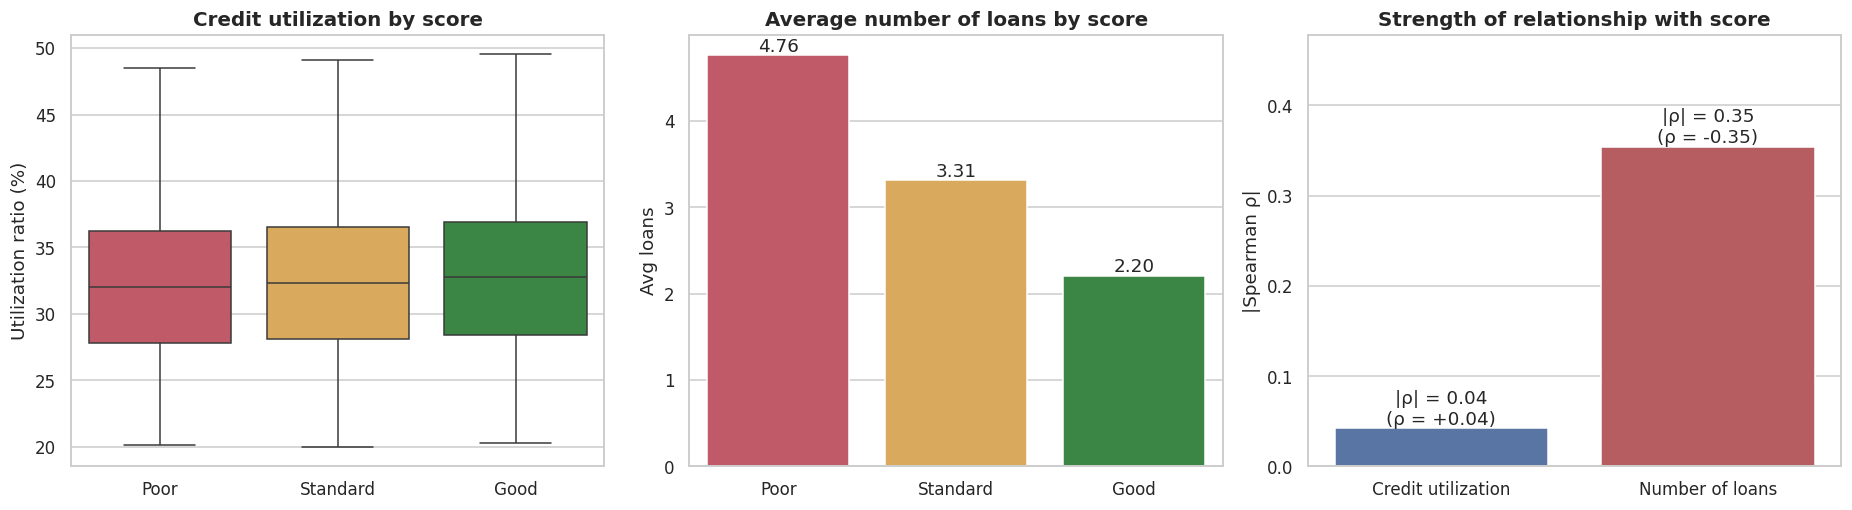

Utilization: rho = +0.042, eps^2 = 0.002 | Loans: rho = -0.354, eps^2 = 0.126


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.boxplot(data=df_copy, x="Credit_Score", y="Credit_Utilization_Ratio", order=SCORE_ORDER, palette=PALETTE,
            showfliers=False, ax=axes[0])
axes[0].set(title="Credit utilization by score", xlabel="", ylabel="Utilization ratio (%)")
loan_mean = df_copy.groupby("Credit_Score", observed=True)["Num_of_Loan"].mean().reindex(SCORE_ORDER)
sns.barplot(x=loan_mean.index, y=loan_mean.values, palette=PALETTE, ax=axes[1])
for i, v in enumerate(loan_mean): axes[1].text(i, v, f"{v:.2f}", ha="center", va="bottom")
axes[1].set(title="Average number of loans by score", xlabel="", ylabel="Avg loans")

rho_u, p_u, _ = spearman_vs_score("Credit_Utilization_Ratio")
rho_l, p_l, _ = spearman_vs_score("Num_of_Loan")
_, _, eps_u = kruskal_by_score("Credit_Utilization_Ratio")
_, _, eps_l = kruskal_by_score("Num_of_Loan")
cmp = pd.Series({"Credit utilization": abs(rho_u), "Number of loans": abs(rho_l)})
sns.barplot(x=cmp.index, y=cmp.values, palette=["#4c72b0", "#c44e52"], ax=axes[2])
for i, (v, r) in enumerate(zip(cmp.values, [rho_u, rho_l])): axes[2].text(i, v, f"|ρ| = {v:.2f}\n(ρ = {r:+.2f})", ha="center", va="bottom")
axes[2].set(title="Strength of relationship with score", xlabel="", ylabel="|Spearman ρ|", ylim=(0, max(cmp.max() * 1.35, 0.1)))
plt.tight_layout(); plt.show()
print(f"Utilization: rho = {rho_u:+.3f}, eps^2 = {eps_u:.3f} | Loans: rho = {rho_l:+.3f}, eps^2 = {eps_l:.3f}")

util_wins = abs(rho_u) > abs(rho_l)
v2 = (f"Supported - utilization (|ρ| = {abs(rho_u):.2f}) matters more than number of loans (|ρ| = {abs(rho_l):.2f})" if util_wins
      else f"Rejected - number of loans (|ρ| = {abs(rho_l):.2f}) matters more than utilization (|ρ| = {abs(rho_u):.2f})")
record("H2", "Utilization ratio has more impact than number of loans?",
       f"|ρ| util = {abs(rho_u):.2f} vs loans = {abs(rho_l):.2f}; ε² {eps_u:.3f} vs {eps_l:.3f}", v2)

##### 1. Why did you pick the specific chart?

Two variables have to be compared on the same yardstick. The box plot and bar chart show each variable against the score; the third panel puts both on one scale (absolute Spearman ρ) so 'which has a greater impact' is answered with a number, not by comparing two differently-scaled charts.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
show(f"""
**Verdict for H2: {v2}.**

**Insight:** Median utilization is {df_copy.groupby('Credit_Score', observed=True)['Credit_Utilization_Ratio'].median().reindex(SCORE_ORDER).round(1).tolist()}%
for Poor / Standard / Good, and the average number of loans is {loan_mean.round(2).tolist()}.
{'Utilization separates the classes more' if util_wins else 'The number of loans separates the classes far more clearly than utilization'}
(effect sizes ε²: utilization {eps_u:.3f}, loans {eps_l:.3f}).

**Business impact:** {'Paisabazaar should weight current card usage heavily in assessment and coach customers to keep utilization low.' if util_wins else
'Debt load (how many loans are already open) is the stronger warning sign; loan-stacking should trigger extra checks before a new loan is recommended, while utilization on its own is a weaker signal than commonly assumed.'}
Recommending yet another loan to a customer who already holds many is the pattern most likely to create defaults (negative growth).
""")


**Verdict for H2: Rejected - number of loans (|ρ| = 0.35) matters more than utilization (|ρ| = 0.04).**

**Insight:** Median utilization is [32.0, 32.3, 32.7]%
for Poor / Standard / Good, and the average number of loans is [4.76, 3.31, 2.2].
The number of loans separates the classes far more clearly than utilization
(effect sizes ε²: utilization 0.002, loans 0.126).

**Business impact:** Debt load (how many loans are already open) is the stronger warning sign; loan-stacking should trigger extra checks before a new loan is recommended, while utilization on its own is a weaker signal than commonly assumed.
Recommending yet another loan to a customer who already holds many is the pattern most likely to create defaults (negative growth).


#### Chart - 9 : H3 – More credit cards → higher score, when utilization is managed well?

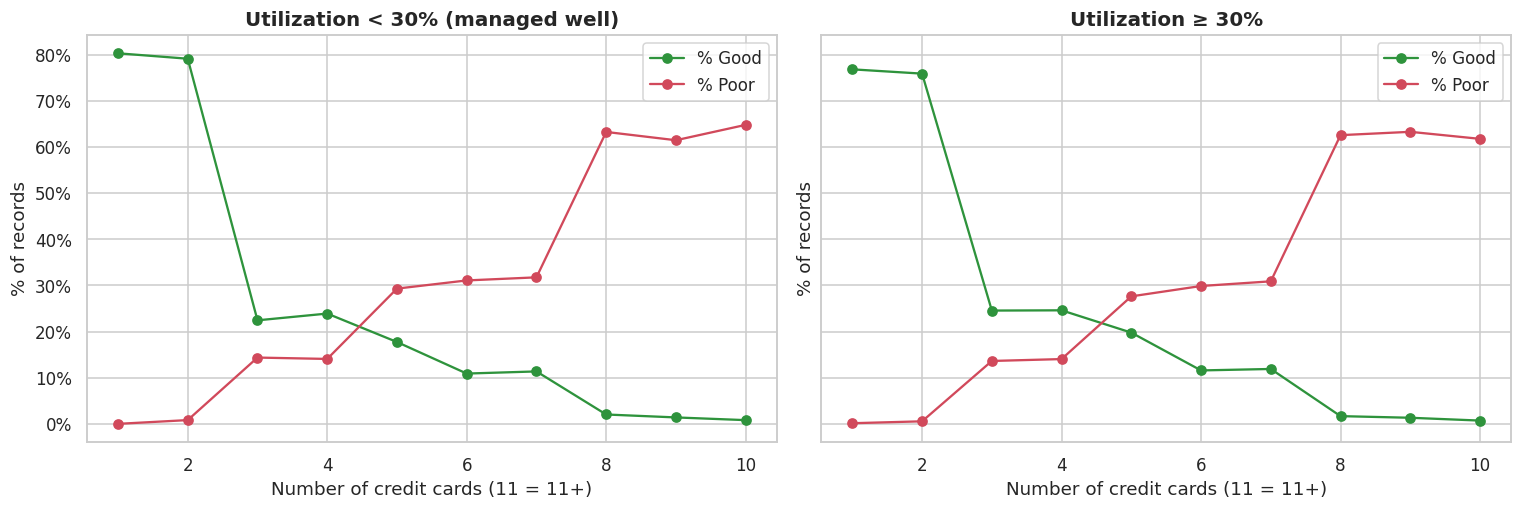

Managed utilization (n=36,362): rho = -0.387 (p < 0.001) | high utilization: rho = -0.384


In [ ]:
util = df_copy["Credit_Utilization_Ratio"]
UTIL_OK = 30 if (util < 30).mean() >= 0.2 else util.median()     # industry rule of thumb: keep utilization under 30%
managed = df_copy[util < UTIL_OK]
high_util = df_copy[util >= UTIL_OK]

def card_profile(d):
    g = d.groupby(d["Num_Credit_Card"].clip(upper=11))
    prof = pd.DataFrame({"pct_good": g["Credit_Score_Num"].apply(lambda s: (s == 2).mean() * 100),
                         "pct_poor": g["Credit_Score_Num"].apply(lambda s: (s == 0).mean() * 100),
                         "n": g.size()})
    return prof[prof.n >= 30]

pm_, ph_ = card_profile(managed), card_profile(high_util)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, prof, label in [(axes[0], pm_, f"Utilization < {UTIL_OK:.0f}% (managed well)"), (axes[1], ph_, f"Utilization ≥ {UTIL_OK:.0f}%")]:
    ax.plot(prof.index, prof.pct_good, marker="o", color=PALETTE["Good"], label="% Good")
    ax.plot(prof.index, prof.pct_poor, marker="o", color=PALETTE["Poor"], label="% Poor")
    ax.set(title=label, xlabel="Number of credit cards (11 = 11+)", ylabel="% of records")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend()
plt.tight_layout(); plt.show()

rho3, p3, n3 = spearman_vs_score("Num_Credit_Card", managed)
rho3h, p3h, _ = spearman_vs_score("Num_Credit_Card", high_util)
print(f"Managed utilization (n={n3:,}): rho = {rho3:+.3f} (p {fmt_p(p3)}) | high utilization: rho = {rho3h:+.3f}")
v3 = verdict_from_rho(rho3, p3, +1)
record("H3", "More credit cards -> higher score (utilization managed well)?",
       f"Spearman ρ = {rho3:+.2f} among utilization < {UTIL_OK:.0f}% (n = {n3:,})", v3)

##### 1. Why did you pick the specific chart?

The hypothesis has a condition ('assuming utilization is managed well'), so the data is first filtered to customers with utilization under 30 % (the common rule of thumb). A line chart suits an ordered count variable (number of cards) and shows the trend in % Good and % Poor. The high-utilization panel is shown next to it as a control, to see whether the condition changes the pattern.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
lo_c, hi_c = pm_.index.min(), pm_.index.max()
show(f"""
**Verdict for H3: {v3}.**

**Insight:** Among customers with utilization below {UTIL_OK:.0f}%, those with {lo_c} card(s) are {pm_.pct_good.loc[lo_c]:.1f}% Good / {pm_.pct_poor.loc[lo_c]:.1f}% Poor,
while those with {hi_c}{'+' if hi_c == 11 else ''} cards are {pm_.pct_good.loc[hi_c]:.1f}% Good / {pm_.pct_poor.loc[hi_c]:.1f}% Poor.
The pattern in the high-utilization group is {'similar' if np.sign(rho3) == np.sign(rho3h) else 'different'} (ρ = {rho3h:+.2f}), so
managing utilization {'does not reverse' if np.sign(rho3) == np.sign(rho3h) else 'changes'} the card-count effect.

**Business impact:** {'Holding more cards is fine for disciplined customers, so cross-selling an extra card to low-utilization customers is low-risk.' if rho3 >= 0.1 else
'Even disciplined customers do not benefit from more cards - a high card count goes with weaker scores. Paisabazaar should be careful about pushing additional cards to customers who already hold many; this is a potential negative-growth pattern where short-term card sales raise long-term risk.'}
""")


**Verdict for H3: Rejected - the relationship is moderate and negative (ρ = -0.39), opposite to the assumption.**

**Insight:** Among customers with utilization below 30%, those with 1 card(s) are 80.3% Good / 0.0% Poor,
while those with 10 cards are 0.8% Good / 64.8% Poor.
The pattern in the high-utilization group is similar (ρ = -0.38), so
managing utilization does not reverse the card-count effect.

**Business impact:** Even disciplined customers do not benefit from more cards - a high card count goes with weaker scores. Paisabazaar should be careful about pushing additional cards to customers who already hold many; this is a potential negative-growth pattern where short-term card sales raise long-term risk.


#### Chart - 10 : H4 – Is there a negative correlation between delayed payments and credit score?

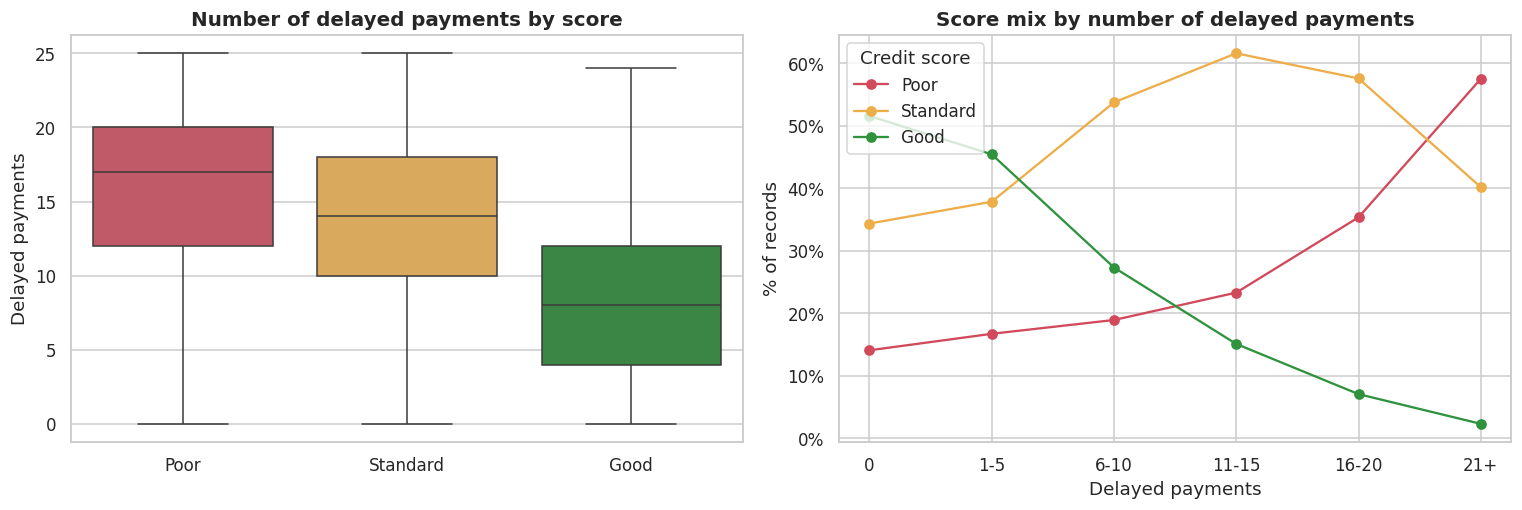

Delayed payments: rho = -0.365 (p < 0.001) | Days delayed from due date: rho = -0.438


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=df_copy, x="Credit_Score", y="Num_of_Delayed_Payment", order=SCORE_ORDER, palette=PALETTE,
            showfliers=False, ax=axes[0])
axes[0].set(title="Number of delayed payments by score", xlabel="", ylabel="Delayed payments")
db = score_shares("Delayed_Bucket")
for s in SCORE_ORDER:
    axes[1].plot(db.index.astype(str), db[s], marker="o", color=PALETTE[s], label=s)
axes[1].set(title="Score mix by number of delayed payments", xlabel="Delayed payments", ylabel="% of records")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter()); axes[1].legend(title="Credit score")
plt.tight_layout(); plt.show()

rho4, p4, n4 = spearman_vs_score("Num_of_Delayed_Payment")
rho4d, p4d, _ = spearman_vs_score("Delay_from_due_date")
print(f"Delayed payments: rho = {rho4:+.3f} (p {fmt_p(p4)}) | Days delayed from due date: rho = {rho4d:+.3f}")
v4 = verdict_from_rho(rho4, p4, -1)
record("H4", "More delayed payments -> lower credit score?", f"Spearman ρ = {rho4:+.2f} (days late ρ = {rho4d:+.2f})", v4)

##### 1. Why did you pick the specific chart?

The box plot shows how the number of delays differs between classes; the line chart over delay buckets shows the dose-response – does risk rise steadily as delays increase? A steady trend is stronger evidence than a single difference in means.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
med_d = df_copy.groupby("Credit_Score", observed=True)["Num_of_Delayed_Payment"].median().reindex(SCORE_ORDER)
show(f"""
**Verdict for H4: {v4}.**

**Insight:** Median delayed payments: Poor {med_d['Poor']:.0f}, Standard {med_d['Standard']:.0f}, Good {med_d['Good']:.0f}.
In the lowest delay bucket ({db.index[0]}) {db['Good'].iloc[0]:.1f}% of records are Good; in the highest ({db.index[-1]}) only {db['Good'].iloc[-1]:.1f}% are.
Days paid late (Delay_from_due_date) tells the same story (ρ = {rho4d:+.2f}).

**Business impact:** Payment discipline is a direct, controllable lever. Paisabazaar can use delay counts as an early-warning
signal for risk and offer auto-pay / reminder tools; every avoided delay moves a customer towards Good. Ignoring repeated
delays when recommending new credit is a clear route to defaults.
""")


**Verdict for H4: Supported - moderate negative relationship (ρ = -0.37).**

**Insight:** Median delayed payments: Poor 17, Standard 14, Good 8.
In the lowest delay bucket (0) 51.6% of records are Good; in the highest (21+) only 2.3% are.
Days paid late (Delay_from_due_date) tells the same story (ρ = -0.44).

**Business impact:** Payment discipline is a direct, controllable lever. Paisabazaar can use delay counts as an early-warning
signal for risk and offer auto-pay / reminder tools; every avoided delay moves a customer towards Good. Ignoring repeated
delays when recommending new credit is a clear route to defaults.


#### Chart - 11 : V1 – Distribution of credit scores across age groups

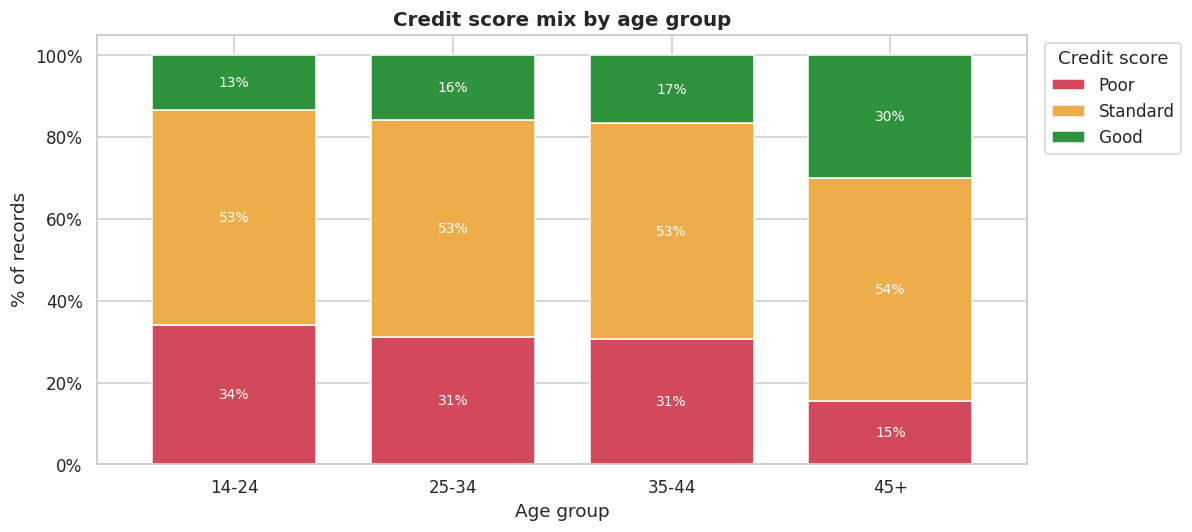

Age group vs score: Cramer's V = 0.126 (p < 0.001) | Age Spearman rho = +0.150


In [ ]:
ags = score_shares("Age_Group")
ax = ags.plot(kind="bar", stacked=True, color=[PALETTE[s] for s in SCORE_ORDER], figsize=(11, 5), width=0.75)
for cont in ax.containers:
    ax.bar_label(cont, labels=[f"{v:.0f}%" if v >= 5 else "" for v in cont.datavalues], label_type="center", color="white", fontsize=9)
ax.set(title="Credit score mix by age group", xlabel="Age group", ylabel="% of records")
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend(title="Credit score", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

fig = px.histogram(df_copy, x="Age", color="Credit_Score", color_discrete_map=PALETTE, barnorm="percent", nbins=40,
                   category_orders={"Credit_Score": SCORE_ORDER}, title="Credit score share by exact age (interactive)")
fig.update_layout(yaxis_title="% of records", yaxis_ticksuffix="%", legend_title_text="Credit score")
fig.show()

v_age, p_age, _, _ = cramers_v(df_copy["Age_Group"], df_copy["Credit_Score"])
rho_age_hist = stats.spearmanr(df_copy["Age"], df_copy["Credit_History_Age"])[0]
rho_age, p_rage, _ = spearman_vs_score("Age")
print(f"Age group vs score: Cramer's V = {v_age:.3f} (p {fmt_p(p_age)}) | Age Spearman rho = {rho_age:+.3f}")

##### 1. Why did you pick the specific chart?

A 100 % stacked bar shows the score composition inside each age group, which is exactly what 'distribution across age groups' asks for, and it is not misled by groups having different sizes. The Plotly version shows the same mix at each exact age so the trend can be inspected interactively.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
best_ag, worst_ag = ags["Good"].idxmax(), ags["Poor"].idxmax()
show(f"""
**Insight:** The share of Good scores is highest in **{best_ag}** ({ags.loc[best_ag, 'Good']:.1f}%) and the share of Poor is highest in
**{worst_ag}** ({ags.loc[worst_ag, 'Poor']:.1f}%). Across groups, Good ranges from {ags['Good'].min():.1f}% to {ags['Good'].max():.1f}%.
The overall association is {strength(v_age)} (Cramér's V = {v_age:.2f}; age ρ = {rho_age:+.2f}) - {'older customers tend to have better scores' if rho_age > 0.1 else 'age by itself is not a strong driver'}. Age and credit-history length are correlated (ρ = {rho_age_hist:+.2f}), so part of the age effect {'is likely explained by longer credit histories' if rho_age_hist > 0.3 else 'is not explained by credit-history length'}.

**Business impact:** {'Younger customers are a natural audience for credit-builder products and financial-literacy content, while older segments are safer targets for premium offers.' if rho_age > 0.1 else 'Age-based targeting alone would add little; behaviour matters more than age.'}
Age must never be used as a sole approval criterion – it is weak as a risk signal and raises fairness concerns.
""")


**Insight:** The share of Good scores is highest in **45+** (30.1%) and the share of Poor is highest in
**14-24** (34.0%). Across groups, Good ranges from 13.3% to 30.1%.
The overall association is weak (Cramér's V = 0.13; age ρ = +0.15) - older customers tend to have better scores. Age and credit-history length are correlated (ρ = +0.22), so part of the age effect is not explained by credit-history length.

**Business impact:** Younger customers are a natural audience for credit-builder products and financial-literacy content, while older segments are safer targets for premium offers.
Age must never be used as a sole approval criterion – it is weak as a risk signal and raises fairness concerns.


#### Chart - 12 : V3 – Trends or seasonal patterns in credit scores by month

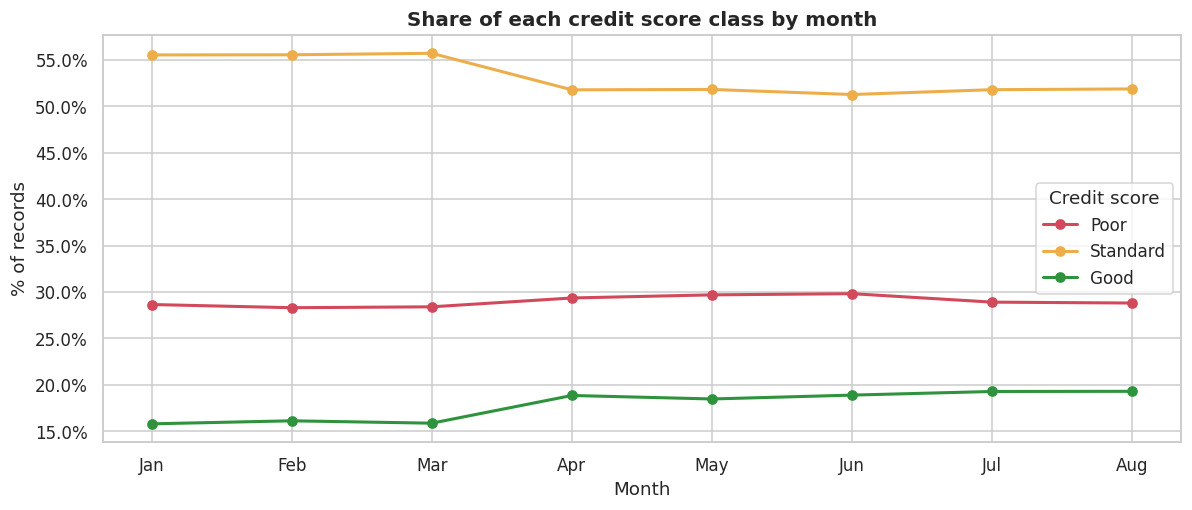

Month vs score: Chi-square = 201.8, dof = 14, p < 0.001, Cramer's V = 0.032; trend slope = +0.0048 per month


In [ ]:
ms = pd.crosstab(df_copy["Month"], df_copy["Credit_Score"], normalize="index").reindex(columns=SCORE_ORDER) * 100
ms.index = [calendar.month_abbr[int(m)] for m in ms.index]
fig, ax = plt.subplots(figsize=(11, 4.8))
for s in SCORE_ORDER:
    ax.plot(ms.index, ms[s], marker="o", color=PALETTE[s], label=s, lw=2)
ax.set(title="Share of each credit score class by month", xlabel="Month", ylabel="% of records")
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend(title="Credit score")
plt.tight_layout(); plt.show()

mean_by_m = df_copy.groupby("Month")["Credit_Score_Num"].mean()
fig = px.line(x=[calendar.month_abbr[int(m)] for m in mean_by_m.index], y=mean_by_m.values, markers=True,
              title="Average credit score (Poor=0, Standard=1, Good=2) by month",
              labels={"x": "Month", "y": "Average score"})
fig.show()

v_m, p_m, chi_m, dof_m = cramers_v(df["Month"], df["Credit_Score"])
slope = np.polyfit(mean_by_m.index.astype(float), mean_by_m.values, 1)[0]
print(f"Month vs score: Chi-square = {chi_m:,.1f}, dof = {dof_m}, p {fmt_p(p_m)}, Cramer's V = {v_m:.3f}; trend slope = {slope:+.4f} per month")

##### 1. Why did you pick the specific chart?

A line chart is the natural choice for change over time. Plotting the share of each class (not raw counts) removes the effect of different record counts per month. A chi-square test with Cramér's V says whether the month-to-month differences are meaningful or just noise.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
n_months = df_copy["Month"].nunique()
show(f"""
**Insight:** Data covers **{n_months} months** ({ms.index[0]}–{ms.index[-1]}) of a single year. The share of Good moves between
{ms['Good'].min():.1f}% and {ms['Good'].max():.1f}%, and Poor between {ms['Poor'].min():.1f}% and {ms['Poor'].max():.1f}%.
The association between month and score is {strength(v_m)} (Cramér's V = {v_m:.3f}); the average score changes by {slope:+.4f} per month,
i.e. {'a gradual upward drift' if slope > 0.005 else 'a gradual downward drift' if slope < -0.005 else 'essentially flat'}.
Because the same customers are tracked every month, any drift reflects customers' credit histories maturing rather than true seasonality,
and {n_months} months is too short to identify a yearly seasonal cycle.

**Business impact:** Credit quality is stable across the observed months, so risk thresholds do not need month-specific adjustment.
A seasonal analysis (e.g. festive-season spending) would need multi-year data – a recommended data-collection improvement.
""")


**Insight:** Data covers **8 months** (Jan–Aug) of a single year. The share of Good moves between
15.8% and 19.3%, and Poor between 28.3% and 29.8%.
The association between month and score is negligible (Cramér's V = 0.032); the average score changes by +0.0048 per month,
i.e. essentially flat.
Because the same customers are tracked every month, any drift reflects customers' credit histories maturing rather than true seasonality,
and 8 months is too short to identify a yearly seasonal cycle.

**Business impact:** Credit quality is stable across the observed months, so risk thresholds do not need month-specific adjustment.
A seasonal analysis (e.g. festive-season spending) would need multi-year data – a recommended data-collection improvement.


#### Chart - 13 : Credit mix and minimum-payment behaviour vs credit score

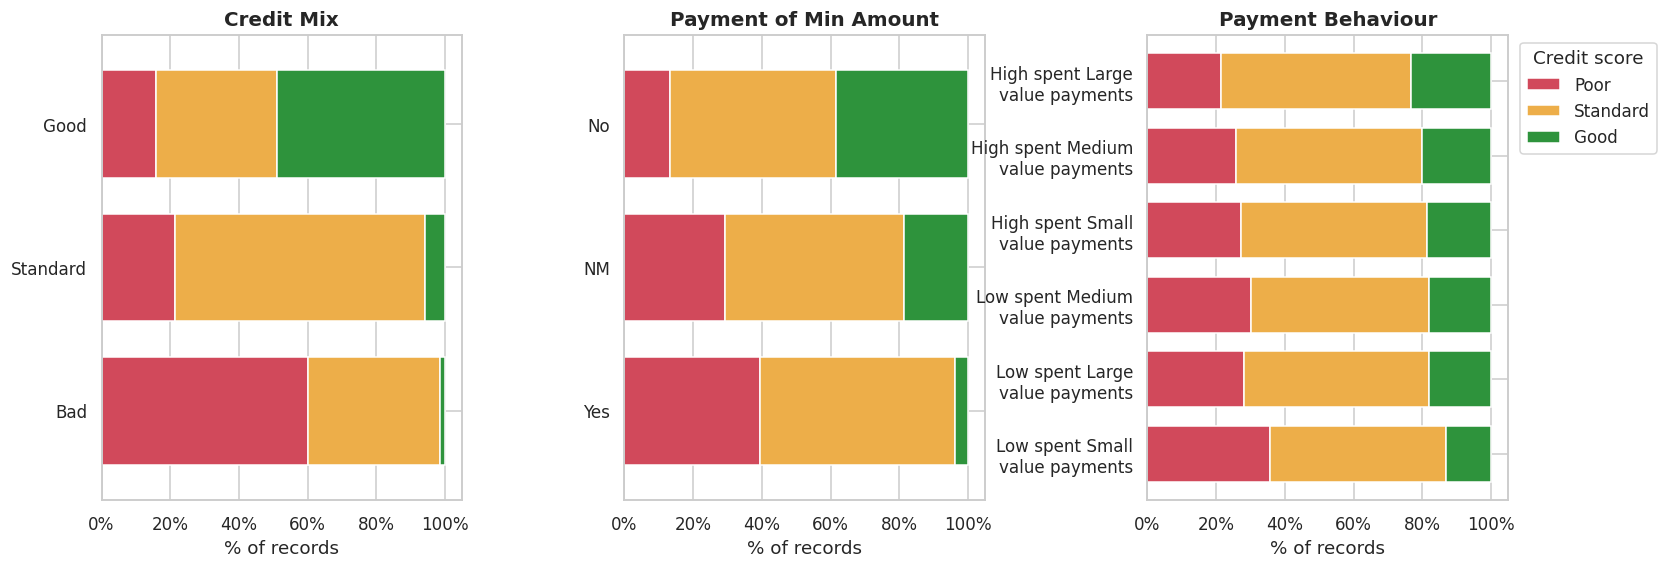

{'Credit_Mix': np.float64(0.45), 'Payment_of_Min_Amount': np.float64(0.313), 'Payment_Behaviour': np.float64(0.088)} <- Cramer's V


In [ ]:
cat_cols = [c for c in ["Credit_Mix", "Payment_of_Min_Amount", "Payment_Behaviour"] if c in df_copy]
fig, axes = plt.subplots(1, len(cat_cols), figsize=(5.5 * len(cat_cols), 5.5), gridspec_kw={"wspace": 0.45})
axes = np.atleast_1d(axes)
cat_strength = {}
for ax, c in zip(axes, cat_cols):
    sh = score_shares(c)
    sh = sh.sort_values("Good")
    sh.index = [textwrap.fill(str(v).replace("_", " "), 18) for v in sh.index]
    sh.plot(kind="barh", stacked=True, color=[PALETTE[s] for s in SCORE_ORDER], ax=ax, legend=False, width=0.75)
    ax.set(title=c.replace("_", " "), xlabel="% of records", ylabel="")
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    cat_strength[c] = cramers_v(df[c], df["Credit_Score"])[0]
axes[-1].legend(SCORE_ORDER, title="Credit score", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()
print({k: round(v, 3) for k, v in cat_strength.items()}, "<- Cramer's V")

##### 1. Why did you pick the specific chart?

Stacked horizontal bars show the score mix inside each category and rank categories by their share of Good. Cramér's V puts the categorical variables on a 0-1 strength scale so they can be compared to each other and to the numeric drivers.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
cmx = score_shares("Credit_Mix")
txt_pm = ""
if "Payment_of_Min_Amount" in df_copy:
    pmx = score_shares("Payment_of_Min_Amount")
    if {"Yes", "No"} <= set(pmx.index):
        txt_pm = (f" Customers who pay only the minimum amount are {pmx.loc['Yes', 'Poor']:.1f}% Poor versus {pmx.loc['No', 'Poor']:.1f}% "
                  f"for those who pay more (Cramér's V = {cat_strength['Payment_of_Min_Amount']:.2f}).")
show(f"""
**Insight:** Credit mix is a {strength(cat_strength['Credit_Mix'])} signal (Cramér's V = {cat_strength['Credit_Mix']:.2f}):
{', '.join(f"{k} mix -> {cmx.loc[k, 'Good']:.1f}% Good / {cmx.loc[k, 'Poor']:.1f}% Poor" for k in cmx.index)}.{txt_pm}
{('Payment behaviour is ' + strength(cat_strength['Payment_Behaviour']) + f" (V = {cat_strength['Payment_Behaviour']:.2f}).") if 'Payment_Behaviour' in cat_strength else ''}

**Business impact:** Credit mix and minimum-payment habits are quick, explainable screening rules for Paisabazaar's advisors.
Customers stuck on minimum payments are both a risk segment and an opportunity for debt-consolidation products.
""")


**Insight:** Credit mix is a moderate signal (Cramér's V = 0.45):
Bad mix -> 1.5% Good / 60.1% Poor, Good mix -> 48.9% Good / 16.0% Poor, Standard mix -> 5.7% Good / 21.5% Poor. Customers who pay only the minimum amount are 39.6% Poor versus 13.4% for those who pay more (Cramér's V = 0.31).
Payment behaviour is negligible (V = 0.09).

**Business impact:** Credit mix and minimum-payment habits are quick, explainable screening rules for Paisabazaar's advisors.
Customers stuck on minimum payments are both a risk segment and an opportunity for debt-consolidation products.


#### Chart - 14 : Which numeric factors are most associated with credit score?

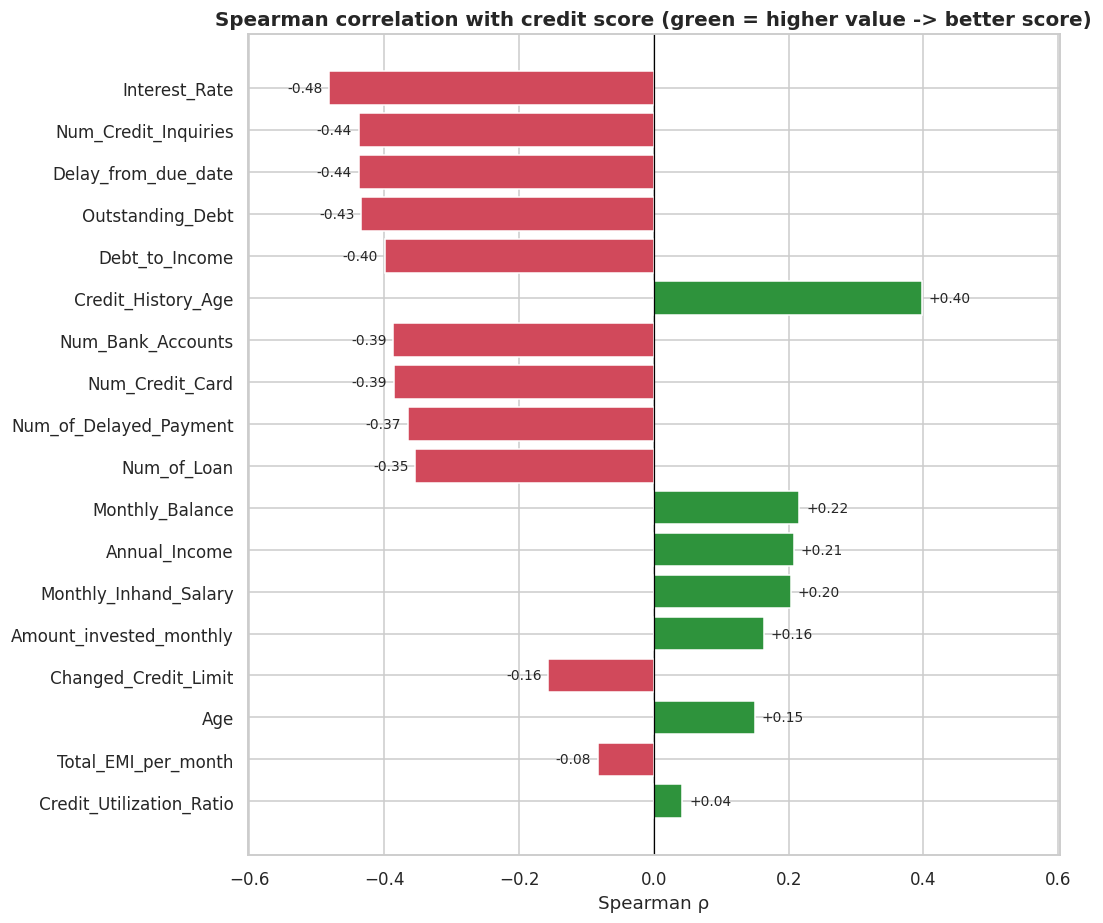

In [ ]:
cand = [c for c in NUM_COLS + ["Credit_History_Age", "Debt_to_Income"] if c in df_copy]
rank = pd.DataFrame([(c, *spearman_vs_score(c)[:2]) for c in cand], columns=["Feature", "rho", "p"])
rank["abs_rho"] = rank["rho"].abs()
rank = rank.sort_values("abs_rho", ascending=True)

fig, ax = plt.subplots(figsize=(10, 0.42 * len(rank) + 1))
colors = [PALETTE["Good"] if r > 0 else PALETTE["Poor"] for r in rank["rho"]]
ax.barh(rank["Feature"], rank["rho"], color=colors)
ax.axvline(0, color="black", lw=0.8)
for y, r in enumerate(rank["rho"]):
    ax.text(r + (0.01 if r >= 0 else -0.01), y, f"{r:+.2f}", va="center", ha="left" if r >= 0 else "right", fontsize=9)
ax.set(title="Spearman correlation with credit score (green = higher value -> better score)", xlabel="Spearman ρ", ylabel="")
lim = rank["abs_rho"].max() * 1.25
ax.set_xlim(-lim, lim); plt.tight_layout(); plt.show()
rank_sorted = rank.sort_values("abs_rho", ascending=False).reset_index(drop=True)

##### 1. Why did you pick the specific chart?

A diverging bar chart of correlations ranks every numeric factor in one view and shows direction (green improves the score, red worsens it). It answers the stakeholder question 'what should we look at first?'

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
top = rank_sorted.head(5)
show(f"""
**Insight:** The five factors most associated with credit score are:
{chr(10).join(f"{i+1}. **{r.Feature}** (ρ = {r.rho:+.2f}, {strength(r.rho)}, {'higher -> better score' if r.rho > 0 else 'higher -> worse score'})" for i, r in top.iterrows())}

Weakest factors: {', '.join(rank_sorted.tail(3)['Feature'])} (|ρ| < {rank_sorted.tail(3)['abs_rho'].max():.2f}).

**Caution on causality:** correlation is not cause. **Interest_Rate** in particular is set *by the lender* based on perceived risk,
so it is partly a *result* of creditworthiness - a strong warning signal, but not a lever the customer pulls directly.
The customer-controllable drivers are payment delays, credit inquiries, number of loans and outstanding debt.

**Business impact:** Assessment effort should focus on the top signals above; customer advice should focus on the controllable ones
(pay on time, avoid repeated applications, reduce debt and loan count), which is where Paisabazaar's advisory products can move scores.
""")


**Insight:** The five factors most associated with credit score are:
1. **Interest_Rate** (ρ = -0.48, moderate, higher -> worse score)
2. **Num_Credit_Inquiries** (ρ = -0.44, moderate, higher -> worse score)
3. **Delay_from_due_date** (ρ = -0.44, moderate, higher -> worse score)
4. **Outstanding_Debt** (ρ = -0.43, moderate, higher -> worse score)
5. **Debt_to_Income** (ρ = -0.40, moderate, higher -> worse score)

Weakest factors: Age, Total_EMI_per_month, Credit_Utilization_Ratio (|ρ| < 0.15).

**Caution on causality:** correlation is not cause. **Interest_Rate** in particular is set *by the lender* based on perceived risk,
so it is partly a *result* of creditworthiness - a strong warning signal, but not a lever the customer pulls directly.
The customer-controllable drivers are payment delays, credit inquiries, number of loans and outstanding debt.

**Business impact:** Assessment effort should focus on the top signals above; customer advice should focus on the controllable ones
(pay on time, avoid repeated applications, reduce debt and loan count), which is where Paisabazaar's advisory products can move scores.


### **Multivariate analysis**

#### Chart - 15 - Correlation Heatmap

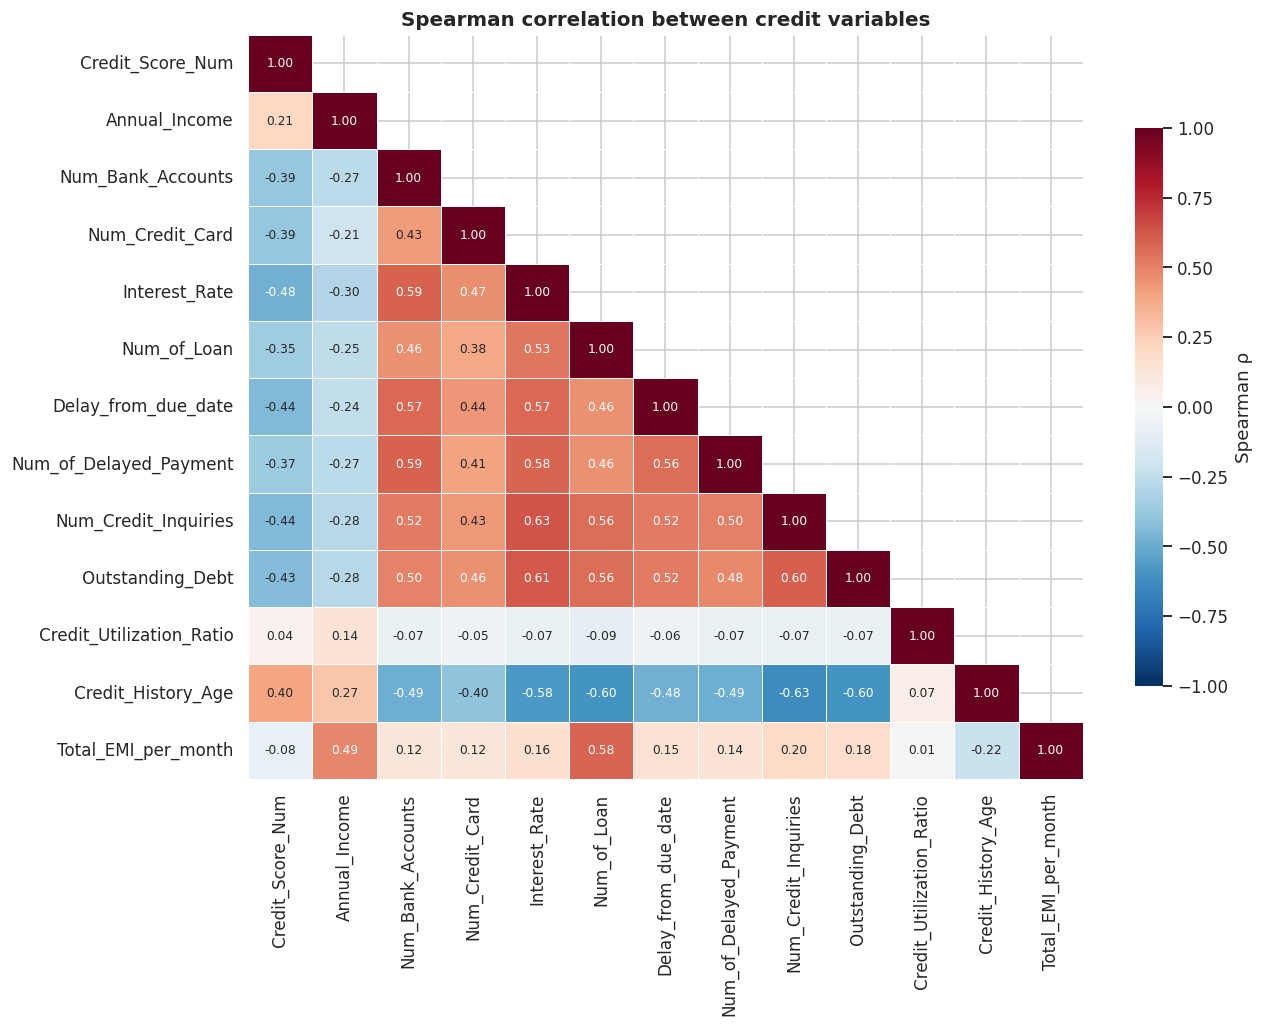

In [ ]:
heat_cols = [c for c in ["Credit_Score_Num", "Annual_Income", "Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate",
                         "Num_of_Loan", "Delay_from_due_date", "Num_of_Delayed_Payment", "Num_Credit_Inquiries",
                         "Outstanding_Debt", "Credit_Utilization_Ratio", "Credit_History_Age", "Total_EMI_per_month"] if c in df_copy]
corr = df_copy[heat_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(12, 9.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={"size": 8}, cbar_kws={"shrink": 0.75, "label": "Spearman ρ"})
plt.title("Spearman correlation between credit variables")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap shows every pair of variables at once. It reveals drivers that move together (multicollinearity) – important because two correlated drivers are not two independent pieces of evidence, and a future model would need to handle them.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
pairs = corr.where(~np.tril(np.ones_like(corr, dtype=bool))).stack()
pairs = pairs.drop([p for p in pairs.index if "Credit_Score_Num" in p], errors="ignore")
top_pairs = pairs.abs().sort_values(ascending=False).head(4)
show(f"""
**Insight:** Strongest relationships between the features themselves:
{chr(10).join(f"- **{a}** & **{b}**: ρ = {pairs[(a, b)]:+.2f}" for a, b in top_pairs.index)}

These drivers form a cluster describing an overall **credit-stress profile** (many loans, many delays, many inquiries,
higher interest rates). They reinforce each other rather than adding independent evidence.

**Business impact:** Paisabazaar can summarise risk with a small number of composite indicators instead of many raw fields,
which keeps advisor rules simple. For a future ML model, correlated features need regularisation or feature selection.
""")


**Insight:** Strongest relationships between the features themselves:
- **Num_Credit_Inquiries** & **Credit_History_Age**: ρ = -0.63
- **Interest_Rate** & **Num_Credit_Inquiries**: ρ = +0.63
- **Interest_Rate** & **Outstanding_Debt**: ρ = +0.61
- **Num_Credit_Inquiries** & **Outstanding_Debt**: ρ = +0.60

These drivers form a cluster describing an overall **credit-stress profile** (many loans, many delays, many inquiries,
higher interest rates). They reinforce each other rather than adding independent evidence.

**Business impact:** Paisabazaar can summarise risk with a small number of composite indicators instead of many raw fields,
which keeps advisor rules simple. For a future ML model, correlated features need regularisation or feature selection.


#### Chart - 16 : Interaction – utilization band × delayed payments → % Good

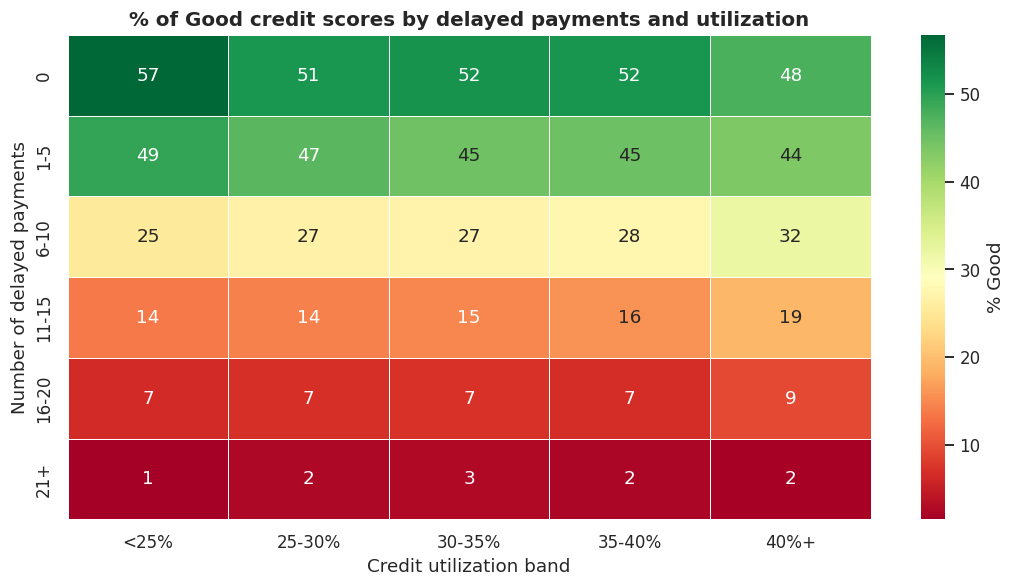

In [ ]:
pivot = df_copy.pivot_table(index="Delayed_Bucket", columns="Utilization_Band", values="Credit_Score_Num",
                       aggfunc=lambda s: (s == 2).mean() * 100, observed=False)
counts_pv = df_copy.pivot_table(index="Delayed_Bucket", columns="Utilization_Band", values="Credit_Score_Num",
                           aggfunc="size", observed=False)
pivot = pivot.where(counts_pv >= 30)      # hide cells with too few records to be reliable
plt.figure(figsize=(10, 5.5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn", cbar_kws={"label": "% Good"}, linewidths=0.5)
plt.title("% of Good credit scores by delayed payments and utilization")
plt.xlabel("Credit utilization band"); plt.ylabel("Number of delayed payments")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A heatmap of a pivot table shows how two drivers act together on the outcome. It checks whether H2 and H4 hold at the same time: does utilization still matter once payment delays are fixed? Cells with fewer than 30 records are blanked so no conclusion rests on tiny samples.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
row_range = (pivot.max(axis=0) - pivot.min(axis=0)).mean()   # effect of delays within a utilization band
col_range = (pivot.max(axis=1) - pivot.min(axis=1)).mean()   # effect of utilization within a delay bucket
show(f"""
**Insight:** Within the same utilization band, moving across delay buckets changes the share of Good by about
**{row_range:.0f} percentage points** on average; within the same delay bucket, moving across utilization bands changes it by about
**{col_range:.0f} points**. So {'payment delays dominate - colour changes mainly from top to bottom' if row_range > col_range else 'utilization dominates - colour changes mainly from left to right'}.

**Business impact:** This confirms the ranking from Charts 8, 10 and 14 while controlling for the other driver. The best-quality
segment (fewest delays) is where Paisabazaar can safely recommend premium products; the high-delay rows are where
reminders, auto-pay and credit-repair guidance will have the most effect.
""")


**Insight:** Within the same utilization band, moving across delay buckets changes the share of Good by about
**50 percentage points** on average; within the same delay bucket, moving across utilization bands changes it by about
**5 points**. So payment delays dominate - colour changes mainly from top to bottom.

**Business impact:** This confirms the ranking from Charts 8, 10 and 14 while controlling for the other driver. The best-quality
segment (fewest delays) is where Paisabazaar can safely recommend premium products; the high-delay rows are where
reminders, auto-pay and credit-repair guidance will have the most effect.


#### Chart - 17 - Pair Plot (plus interactive debt vs delay view)

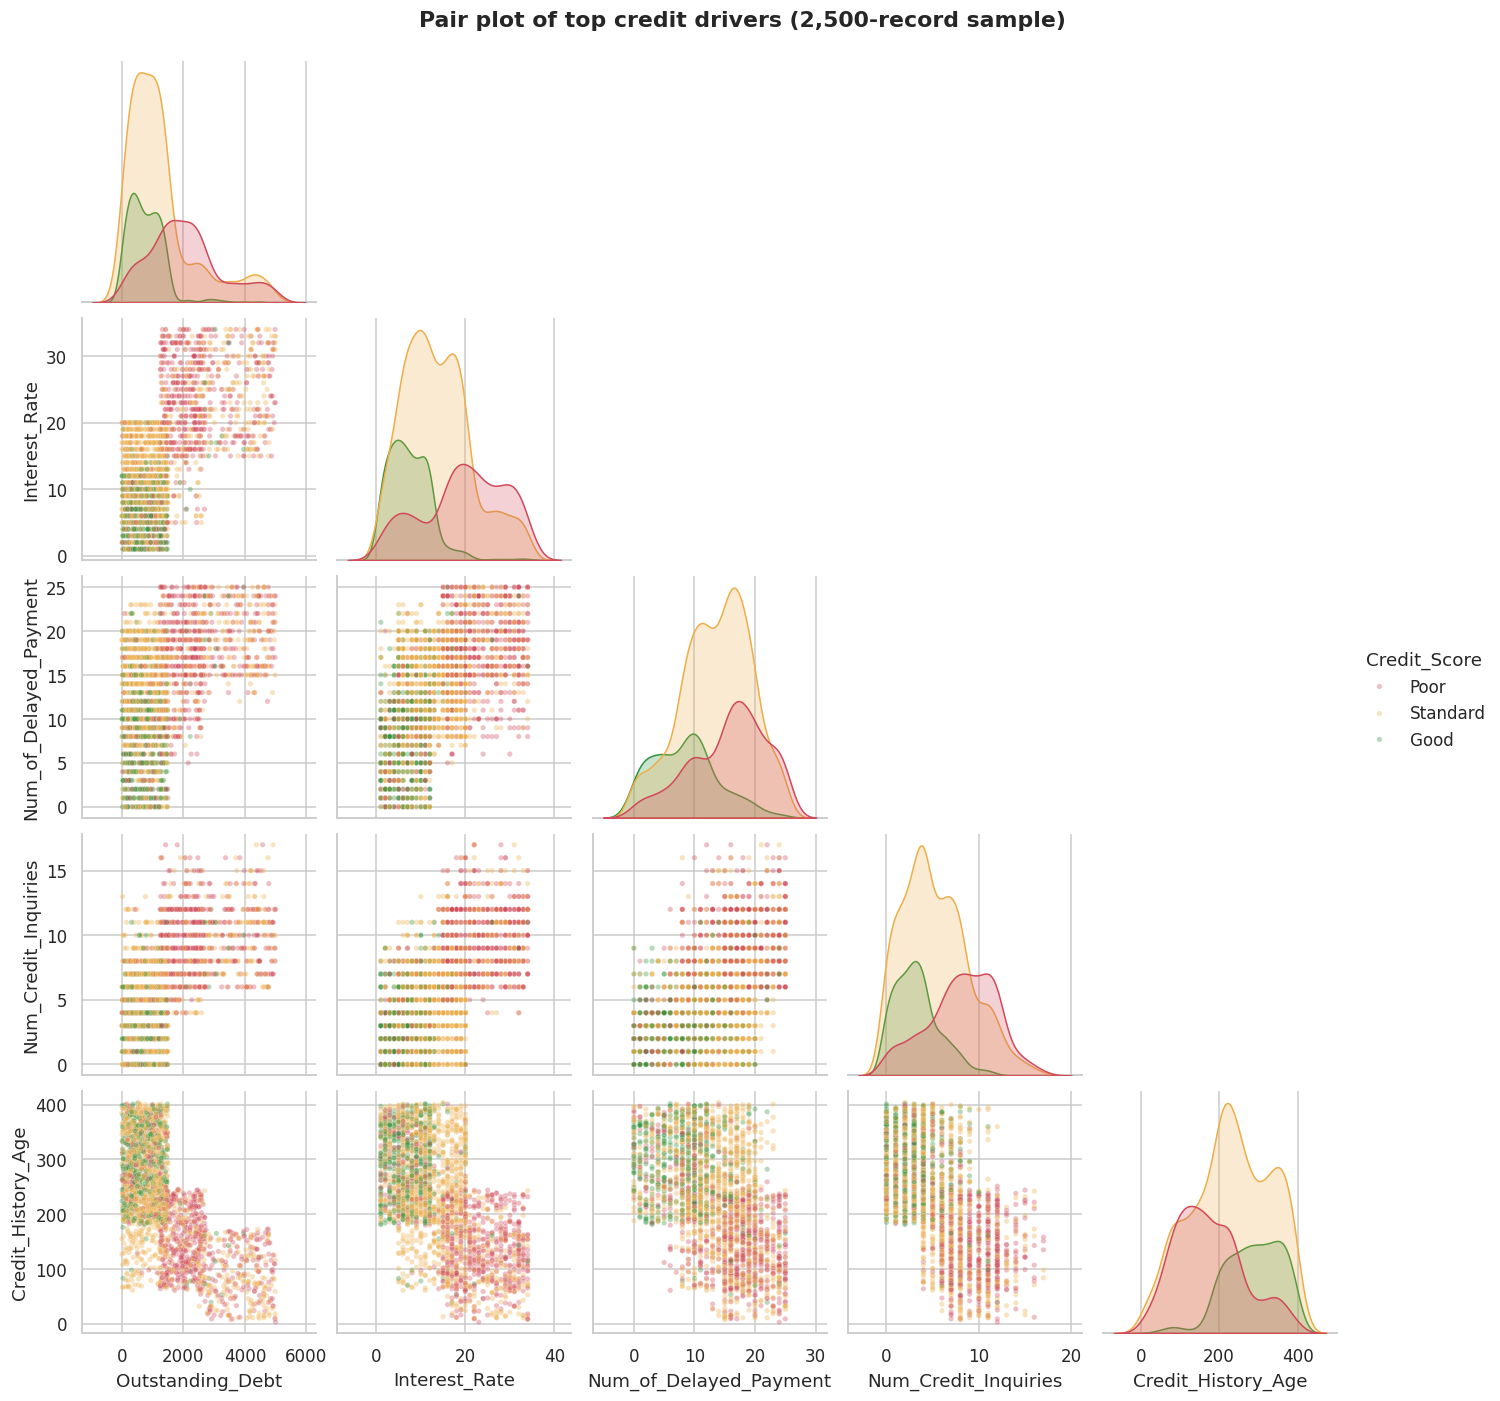

In [ ]:
pair_cols = [c for c in ["Outstanding_Debt", "Interest_Rate", "Num_of_Delayed_Payment", "Num_Credit_Inquiries",
                         "Credit_History_Age"] if c in df_copy]
sample = df_copy.sample(min(2500, len(df_copy)), random_state=42)
g = sns.pairplot(sample, vars=pair_cols, hue="Credit_Score", hue_order=SCORE_ORDER, palette=PALETTE,
                 plot_kws={"alpha": 0.35, "s": 12}, diag_kind="kde", corner=True)
g.fig.suptitle("Pair plot of top credit drivers (2,500-record sample)", y=1.02, fontweight="bold")
plt.show()

fig = px.scatter(sample, x="Delay_from_due_date", y="Outstanding_Debt", color="Credit_Score",
                 color_discrete_map=PALETTE, category_orders={"Credit_Score": SCORE_ORDER}, opacity=0.55,
                 hover_data=["Annual_Income", "Num_of_Loan", "Num_Credit_Card"],
                 title="Outstanding debt vs days paid late (hover for customer details)",
                 labels={"Delay_from_due_date": "Avg days paid after due date", "Outstanding_Debt": "Outstanding debt"})
fig.show()

##### 1. Why did you pick the specific chart?

A pair plot shows the joint distribution of several drivers coloured by score, revealing where the classes separate and where they overlap. A random sample keeps it readable and fast. The Plotly scatter lets a stakeholder hover over individual customers to see the profile behind each point.

##### 2. What is/are the insight(s) found from the chart?
##### 3. Will the gained insights help create a positive business impact? Are there any insights that lead to negative growth?

*Both answers below are generated from the data in the next cell, so they stay correct if the dataset is updated.*

In [ ]:
zone = df_copy.groupby("Credit_Score", observed=True)[["Outstanding_Debt", "Delay_from_due_date"]].median().reindex(SCORE_ORDER)
show(f"""
**Insight:** Good customers cluster at **low debt and few days late** (median debt {zone.loc['Good', 'Outstanding_Debt']:,.0f},
median {zone.loc['Good', 'Delay_from_due_date']:.0f} days late) while Poor customers spread into **high debt / long delays**
(median debt {zone.loc['Poor', 'Outstanding_Debt']:,.0f}, {zone.loc['Poor', 'Delay_from_due_date']:.0f} days late).
The classes overlap in the middle, so no single variable cleanly separates them - a combined (multivariate) view or model is needed.

**Business impact:** Simple two-factor rules (debt + lateness) already flag most high-risk customers. The overlap zone is where
Paisabazaar would gain most from a predictive model rather than manual rules.
""")


**Insight:** Good customers cluster at **low debt and few days late** (median debt 736,
median 10 days late) while Poor customers spread into **high debt / long delays**
(median debt 1,945, 27 days late).
The classes overlap in the middle, so no single variable cleanly separates them - a combined (multivariate) view or model is needed.

**Business impact:** Simple two-factor rules (debt + lateness) already flag most high-risk customers. The overlap zone is where
Paisabazaar would gain most from a predictive model rather than manual rules.


## **5. Solution to Business Objective**

### Did the assumptions turn out to be right?

In [ ]:
hyp = pd.DataFrame(HYPOTHESES)
display(hyp.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]).hide(axis="index"))

ID,Question,Evidence,Verdict
H1,Higher annual income -> higher credit score?,Spearman ρ = +0.21; ε² = 0.043,Supported - weak positive relationship (ρ = +0.21)
H2,Utilization ratio has more impact than number of loans?,|ρ| util = 0.04 vs loans = 0.35; ε² 0.002 vs 0.126,Rejected - number of loans (|ρ| = 0.35) matters more than utilization (|ρ| = 0.04)
H3,More credit cards -> higher score (utilization managed well)?,"Spearman ρ = -0.39 among utilization < 30% (n = 36,362)","Rejected - the relationship is moderate and negative (ρ = -0.39), opposite to the assumption"
H4,More delayed payments -> lower credit score?,Spearman ρ = -0.37 (days late ρ = -0.44),Supported - moderate negative relationship (ρ = -0.37)


### What do you suggest the client to achieve the Business Objective?

In [ ]:
ACTIONS = {
    "Num_of_Delayed_Payment": "Use delayed-payment count as an early-warning flag; offer auto-debit and reminder tools to customers with repeated delays.",
    "Delay_from_due_date": "Track how many days late payments are; push due-date reminders a few days before the due date.",
    "Outstanding_Debt": "Check existing debt before recommending new credit; offer debt-consolidation products to high-debt customers.",
    "Interest_Rate": "High card interest rates signal riskier customers; offer balance-transfer / lower-rate products to move them to better terms.",
    "Num_Credit_Inquiries": "Many recent credit inquiries indicate credit hunger; avoid recommending multiple simultaneous applications.",
    "Num_of_Loan": "Guard against loan stacking: add a check before recommending an additional loan to customers who already hold several.",
    "Num_Credit_Card": "Do not blindly cross-sell extra cards to customers who already hold many.",
    "Num_Bank_Accounts": "A very high number of bank accounts goes with weaker scores; treat it as a secondary risk flag.",
    "Credit_History_Age": "Longer credit history helps; offer credit-builder products to customers with short histories.",
    "Credit_Utilization_Ratio": "Coach customers to keep utilization low and alert them when card usage climbs.",
    "Annual_Income": "Use income as one input for loan size, not as the approval gatekeeper.",
    "Debt_to_Income": "Use debt-to-income to size loans so EMIs stay affordable.",
    "Total_EMI_per_month": "Cap new EMIs relative to current EMI burden.",
}
lines = ["**Priority actions, ordered by the strength of each driver in this data:**", ""]
k = 0
for i, r in rank_sorted.head(6).iterrows():
    k += 1
    lines.append(f"{k}. **{r.Feature}** ({'higher -> worse' if r.rho < 0 else 'higher -> better'}, ρ = {r.rho:+.2f}): "
                 + ACTIONS.get(r.Feature, "Monitor this factor in credit assessment."))
lines += [f"{k + 1}. **Credit mix / minimum payments** (Cramér's V = {cat_strength.get('Credit_Mix', 0):.2f} / "
          f"{cat_strength.get('Payment_of_Min_Amount', 0):.2f}): add both as quick screening rules for advisors.",
          "", "**How stakeholders benefit:**",
          "- **Risk & underwriting team:** a ranked, evidence-backed list of risk signals to sharpen approval rules and reduce defaults.",
          "- **Product & marketing team:** clear segments - low-delay / low-debt customers for premium cards and loans, "
          "high-delay or high-debt customers for consolidation and credit-builder products.",
          "- **Customer advisory:** personalised, explainable advice (\"reduce delays\", \"lower your debt\") tied to the factors that move the score.",
          "- **Data / ML team:** validated features and known pitfalls (class imbalance, correlated drivers, panel structure) for a credit-score classifier."]
show("\n".join(lines))

**Priority actions, ordered by the strength of each driver in this data:**

1. **Interest_Rate** (higher -> worse, ρ = -0.48): High card interest rates signal riskier customers; offer balance-transfer / lower-rate products to move them to better terms.
2. **Num_Credit_Inquiries** (higher -> worse, ρ = -0.44): Many recent credit inquiries indicate credit hunger; avoid recommending multiple simultaneous applications.
3. **Delay_from_due_date** (higher -> worse, ρ = -0.44): Track how many days late payments are; push due-date reminders a few days before the due date.
4. **Outstanding_Debt** (higher -> worse, ρ = -0.43): Check existing debt before recommending new credit; offer debt-consolidation products to high-debt customers.
5. **Debt_to_Income** (higher -> worse, ρ = -0.40): Use debt-to-income to size loans so EMIs stay affordable.
6. **Credit_History_Age** (higher -> better, ρ = +0.40): Longer credit history helps; offer credit-builder products to customers with short histories.
7. **Credit mix / minimum payments** (Cramér's V = 0.45 / 0.31): add both as quick screening rules for advisors.

**How stakeholders benefit:**
- **Risk & underwriting team:** a ranked, evidence-backed list of risk signals to sharpen approval rules and reduce defaults.
- **Product & marketing team:** clear segments - low-delay / low-debt customers for premium cards and loans, high-delay or high-debt customers for consolidation and credit-builder products.
- **Customer advisory:** personalised, explainable advice ("reduce delays", "lower your debt") tied to the factors that move the score.
- **Data / ML team:** validated features and known pitfalls (class imbalance, correlated drivers, panel structure) for a credit-score classifier.

# **Conclusion**

In [ ]:
supported = [h["ID"] for h in HYPOTHESES if h["Verdict"].startswith("Supported")]
rejected = [h["ID"] for h in HYPOTHESES if not h["Verdict"].startswith("Supported")]
best = rank_sorted.iloc[0]
CONTROLLABLE = ["Delay_from_due_date", "Num_of_Delayed_Payment", "Num_Credit_Inquiries", "Num_of_Loan",
                "Outstanding_Debt", "Num_Credit_Card", "Credit_Utilization_Ratio"]
best_ctrl = rank_sorted[rank_sorted["Feature"].isin(CONTROLLABLE)].iloc[0]
show(f"""
- **Assumptions:** {len(supported)} of {len(HYPOTHESES)} were supported by the data ({', '.join(supported) or 'none'});
  {', '.join(rejected) or 'none'} {'were' if len(rejected) != 1 else 'was'} not supported or reversed - see the table above. Testing assumptions instead of
  accepting them changed the story: popular beliefs about credit (e.g. on utilization or card count) do not all hold in this customer base.
- **Most important insight:** credit score is driven mainly by **repayment behaviour and debt load**, not by demographics such as age
  or occupation. The strongest single signal is **{best.Feature}** (ρ = {best.rho:+.2f}){' - a lender-assigned rate that reflects risk' if best.Feature == 'Interest_Rate' else ''};
  the strongest factor a customer can control is **{best_ctrl.Feature}** (ρ = {best_ctrl.rho:+.2f}), which makes it the most actionable finding.
- **Assumptions that failed are the most useful findings:** {'number of loans matters far more than utilization (H2)' if 'H2' in rejected else ''}{'; ' if 'H2' in rejected and 'H3' in rejected else ''}{'more credit cards go with worse scores even when utilization is low (H3)' if 'H3' in rejected else ''}.
- **Income** matters (H1: {next(h['Verdict'] for h in HYPOTHESES if h['ID'] == 'H1').split(' - ')[0].lower()}) but customers at every income level appear in every score class.
- **Seasonality:** no meaningful month effect in the {df_copy['Month'].nunique()} months observed (Cramér's V = {v_m:.3f}).
""")


- **Assumptions:** 2 of 4 were supported by the data (H1, H4);
  H2, H3 were not supported or reversed - see the table above. Testing assumptions instead of
  accepting them changed the story: popular beliefs about credit (e.g. on utilization or card count) do not all hold in this customer base.
- **Most important insight:** credit score is driven mainly by **repayment behaviour and debt load**, not by demographics such as age
  or occupation. The strongest single signal is **Interest_Rate** (ρ = -0.48) - a lender-assigned rate that reflects risk;
  the strongest factor a customer can control is **Num_Credit_Inquiries** (ρ = -0.44), which makes it the most actionable finding.
- **Assumptions that failed are the most useful findings:** number of loans matters far more than utilization (H2); more credit cards go with worse scores even when utilization is low (H3).
- **Income** matters (H1: supported) but customers at every income level appear in every score class.
- **Seasonality:** no meaningful month effect in the 8 months observed (Cramér's V = 0.032).


**What I learned**
- Real credit data needs domain-aware cleaning: placeholder strings, numbers stored as text and impossible values had to be fixed, and repairing values from the *same customer's other months* gave far more consistent data than global imputation.
- With ~100k rows almost every test is "significant", so effect sizes (ρ, ε², Cramér's V) are what separate meaningful findings from noise.
- Conditional hypotheses (H3) must be tested on the filtered population the condition describes, with a control group for comparison.

**Future improvements**
- **Predictive modelling:** train a multiclass classifier (Logistic Regression baseline → Random Forest / XGBoost) with customer-grouped train/test splits to avoid leakage between months of the same customer, class weighting for imbalance, and SHAP values to explain individual predictions to advisors.
- **Dashboarding:** publish the cleaned data to Power BI / Tableau / Plotly Dash with filters for age group, income band and credit mix so risk teams can monitor drivers monthly.
- **Deeper analysis:** customer-level transition analysis (who moves from Standard to Good and why), loan-type breakdown from `Type_of_Loan`, and multi-year data to study real seasonality.